In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
# locate workspace local
current = Path.cwd().resolve()
if (current / "src").exists():
    project_root = current
elif (current.parent / "src").exists():
    project_root = current.parent
else:
    project_root = Path(r"F:\Learning\HUST_DOCUMENTS\MI3390-DoAn2\workspace")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"Project root: {project_root}")

Project root: F:\Learning\HUST_DOCUMENTS\MI3390-DoAn2\workspace


In [3]:
from src.utils.spark_utils import get_spark_session
spark = get_spark_session("LaptopPricing_EDA")
print(f"Spark Version: {spark.version}")

Spark Version: 4.2.1


---
# OVERVIEW
---

In [4]:
silver_path = str(project_root / "data" / "processed" / "silver_layer")
print(f"Đọc dữ liệu từ: {silver_path}")

df_spark = spark.read.parquet(silver_path)

print(f"Tổng số bản ghi: {df_spark.count():,}")
df_spark.printSchema()

Đọc dữ liệu từ: F:\Learning\HUST_DOCUMENTS\MI3390-DoAn2\workspace\data\processed\silver_layer
Tổng số bản ghi: 3,698
root
 |-- post_id: string (nullable = true)
 |-- target_price: float (nullable = true)
 |-- raw_cpu: string (nullable = true)
 |-- raw_ram: string (nullable = true)
 |-- raw_hard_drive: string (nullable = true)
 |-- raw_hard_drive_type: string (nullable = true)
 |-- pc_brand: integer (nullable = true)
 |-- pc_cpu: integer (nullable = true)
 |-- pc_ram: integer (nullable = true)
 |-- laptop_screen_size: integer (nullable = true)
 |-- elt_condition: integer (nullable = true)
 |-- elt_origin: integer (nullable = true)
 |-- elt_warranty: integer (nullable = true)
 |-- region_name: string (nullable = true)
 |-- ward_name: string (nullable = true)
 |-- seller_rating: float (nullable = true)
 |-- seller_sold_count: integer (nullable = true)
 |-- crawled_at: timestamp (nullable = true)
 |-- url: string (nullable = true)
 |-- is_seller_rating_missing: integer (nullable = true)
 |

In [5]:
df = df_spark.toPandas()
print(f"Kích thước DataFrame Pandas: {df.shape}")
display(df.head())

Kích thước DataFrame Pandas: (3698, 52)


,post_id,target_price,raw_cpu,raw_ram,raw_hard_drive,raw_hard_drive_type,pc_brand,pc_cpu,pc_ram,laptop_screen_size,...,battery_condition,warranty_months,warranty_type,has_warranty,is_upgraded,repair_status,year_production,year_purchase,bundles,has_bundle
0,80084278,4500000.0,Intel Core i7,8 GB,256 GB,SSD,5,8.0,6.0,5.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,balo đựng laptop,1
1,92604131,4600000.0,Intel Core i7,8 GB,256 GB,SSD,5,8.0,6.0,4.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,cặp đựng laptop trị giá 200k laptopmd chuyên k...,1
2,104284514,7300000.0,Intel Core i7,8 GB,256 GB,SSD,5,8.0,6.0,4.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,túi + chuột không dây ⚡️free ship tận nhà nội ...,1
3,104831770,6500000.0,Intel Core i5,8 GB,256 GB,SSD,5,7.0,6.0,4.0,...,NaN,3.0,cua_hang,1,NaN,original,NaN,NaN,cặp đựng laptop trị giá 200k cam kết của cửa h...,1
4,105004675,7200000.0,Intel Core i5,16 GB,256 GB,SSD,7,7.0,7.0,4.0,...,NaN,NaN,cua_hang,1,NaN,original,NaN,NaN,NaN,0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3698 entries, 0 to 3697
Data columns (total 52 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   post_id                   3698 non-null   str           
 1   target_price              3698 non-null   float32       
 2   raw_cpu                   3490 non-null   str           
 3   raw_ram                   3537 non-null   str           
 4   raw_hard_drive            3385 non-null   str           
 5   raw_hard_drive_type       3295 non-null   str           
 6   pc_brand                  3698 non-null   int32         
 7   pc_cpu                    3490 non-null   float64       
 8   pc_ram                    3537 non-null   float64       
 9   laptop_screen_size        3016 non-null   float64       
 10  elt_condition             3698 non-null   int32         
 11  elt_origin                1284 non-null   float64       
 12  elt_warranty              3698 

In [7]:
df.describe()

,target_price,pc_brand,pc_cpu,pc_ram,laptop_screen_size,elt_condition,elt_origin,elt_warranty,seller_rating,seller_sold_count,...,condition_pct,battery_pct,battery_cycles,battery_hours,warranty_months,has_warranty,is_upgraded,year_production,year_purchase,has_bundle
count,3698.0,3698.000000,3490.000000,3537.000000,3016.000000,3698.000000,1284.000000,3698.000000,2823.000000,3698.000000,...,82.000000,237.000000,12.000000,238.000000,1100.000000,3698.000000,74.0,54.000000,6.000000,3698.000000
mean,11243385.0,5.571390,10.020630,6.538309,4.427056,1.975122,5.471184,0.981882,4.727595,232.768524,...,97.390244,94.805907,100.500000,3.271429,3.581818,0.545430,1.0,2021.148148,2023.833333,0.254191
min,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,...,80.000000,60.000000,3.000000,1.000000,0.000000,0.000000,1.0,2015.000000,2021.000000,0.000000
25%,4500000.0,4.000000,7.000000,6.000000,4.000000,2.000000,1.000000,-1.000000,4.700000,7.000000,...,97.000000,91.000000,10.000000,2.000000,1.000000,0.000000,1.0,2020.000000,2023.000000,0.000000
50%,8100000.0,5.000000,8.000000,6.000000,4.000000,2.000000,7.000000,-1.000000,4.900000,47.000000,...,98.000000,99.000000,56.000000,3.000000,3.000000,1.000000,1.0,2022.000000,2023.500000,0.000000
75%,14900000.0,6.000000,9.000000,7.000000,5.000000,2.000000,8.000000,3.000000,5.000000,259.000000,...,99.000000,100.000000,161.250000,4.000000,3.000000,1.000000,1.0,2023.000000,2025.500000,1.000000
max,123457688.0,20.000000,54.000000,29.000000,8.000000,3.000000,10.000000,8.000000,5.000000,32534.000000,...,100.000000,100.000000,390.000000,16.000000,36.000000,1.000000,1.0,2026.000000,2026.000000,1.000000
std,10289695.0,3.134426,5.937491,1.609420,0.649519,0.205227,3.104309,2.674264,0.493264,693.373577,...,2.646946,7.227851,118.166677,1.497460,3.366543,0.497999,0.0,2.277100,1.940790,0.435465


In [8]:
missing_pct = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage (%)': missing_pct
}).sort_values(by='Missing Percentage (%)', ascending=False)

print("Top 15 cột thiếu dữ liệu nhiều nhất:")
display(missing_summary[missing_summary['Missing Percentage (%)'] > 0].head(15))

Top 15 cột thiếu dữ liệu nhiều nhất:


,Missing Count,Missing Percentage (%)
year_purchase,3692,99.837750
battery_cycles,3686,99.675500
is_new_seal,3655,98.837209
year_production,3644,98.539751
is_upgraded,3624,97.998918
condition_pct,3616,97.782585
origin_country,3522,95.240671
battery_pct,3461,93.591130
battery_hours,3460,93.564089
battery_condition,3394,91.779340


---
# TARGET VARIABLE
---

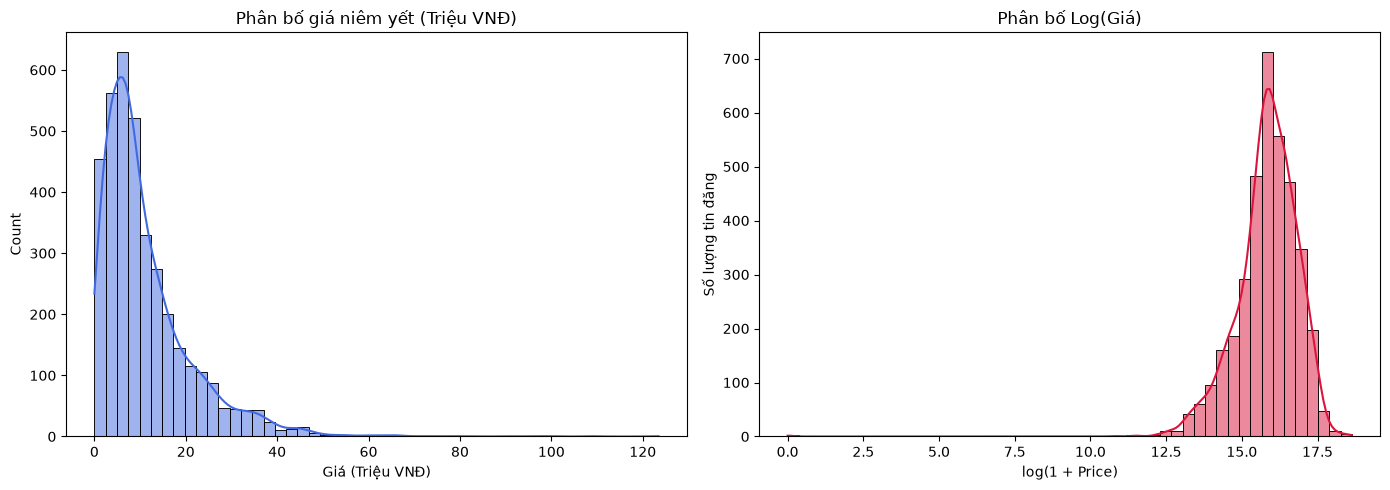

In [9]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['target_price'].dropna() / 1e6, bins=50, kde=True, color='royalblue')
plt.title("Phân bố giá niêm yết (Triệu VNĐ)")
plt.xlabel("Giá (Triệu VNĐ)")

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['target_price'].dropna()), bins=50, kde=True, color='crimson')
plt.title("Phân bố Log(Giá)")
plt.xlabel("log(1 + Price)")
plt.ylabel("Số lượng tin đăng")
plt.ylabel("Số lượng tin đăng")

plt.tight_layout()
plt.show()

In [10]:
price_desc = (df['target_price'] / 1e6).describe()
print("Thống kê mô tả giá (Triệu VNĐ):")
price_desc

Thống kê mô tả giá (Triệu VNĐ):


count    3698.000000
mean       11.243385
std        10.289695
min         0.000000
25%         4.500000
50%         8.100000
75%        14.900000
max       123.457687
Name: target_price, dtype: float64

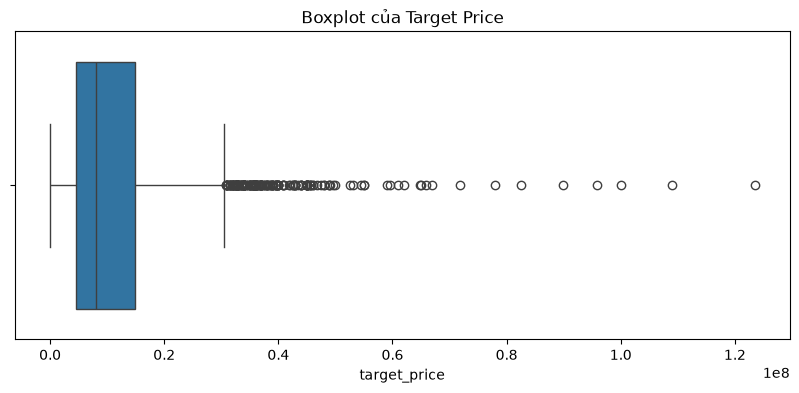

In [11]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['target_price'])
plt.title("Boxplot của Target Price")
plt.show()

---
# UNIVARIATE ANALYSIS
---

## Brand (thương hiệu)

In [12]:
df['brand_name'].unique()

<StringArray>
[     'dell',    'lenovo',   'fujitsu',     'apple',   'toshiba',        'hp',
 'microsoft',      'asus',      'acer',         nan,   'samsung',       'msi',
    'xiaomi',    'huawei',        'lg']
Length: 15, dtype: str

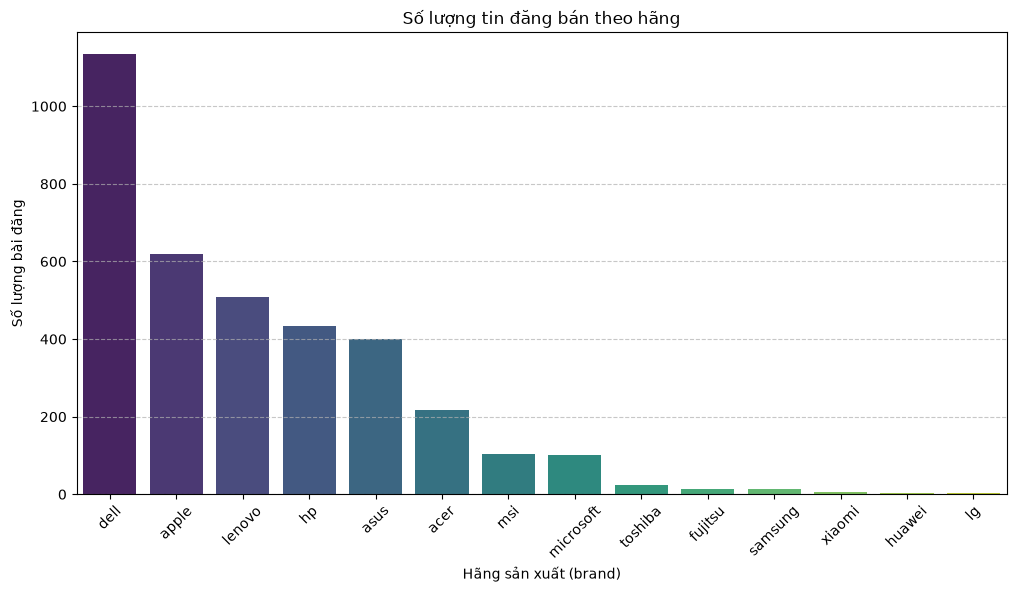

In [13]:
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df, 
    x='brand_name', 
    order=df['brand_name'].value_counts().index, 
    palette='viridis' # Bảng màu gradient
)
plt.title("Số lượng tin đăng bán theo hãng")
plt.xlabel("Hãng sản xuất (brand)")
plt.ylabel("Số lượng bài đăng")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [14]:
null_brand = df['brand_name'].isnull().sum()
print(f"Số lượng tin đăng không trích xuất được hãng máy: {null_brand}, chiếm {(null_brand/df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng tin đăng không trích xuất được hãng máy: 113, chiếm 3.06% tổng số bài đăng


## Product line (Dòng máy)

In [15]:
df['product_line'].unique()

<StringArray>
[   'precision 3510',     'latitude 7490',    'latitude e7400',
               'xps',      'thinkpad t14',     'latitude 7420',
                 nan,    'precision 3541',     'latitude 5510',
    'precision 7550',
 ...
     'latitude 7650',     'inspiron 7510',     'latitude 7470',
     'thinkpad p16s',     'thinkpad t450', 'elitebook 645 g10',
    'probook 650 g8',     'latitude 7240',     'inspiron 3541',
    'thinkpad t480s']
Length: 485, dtype: str

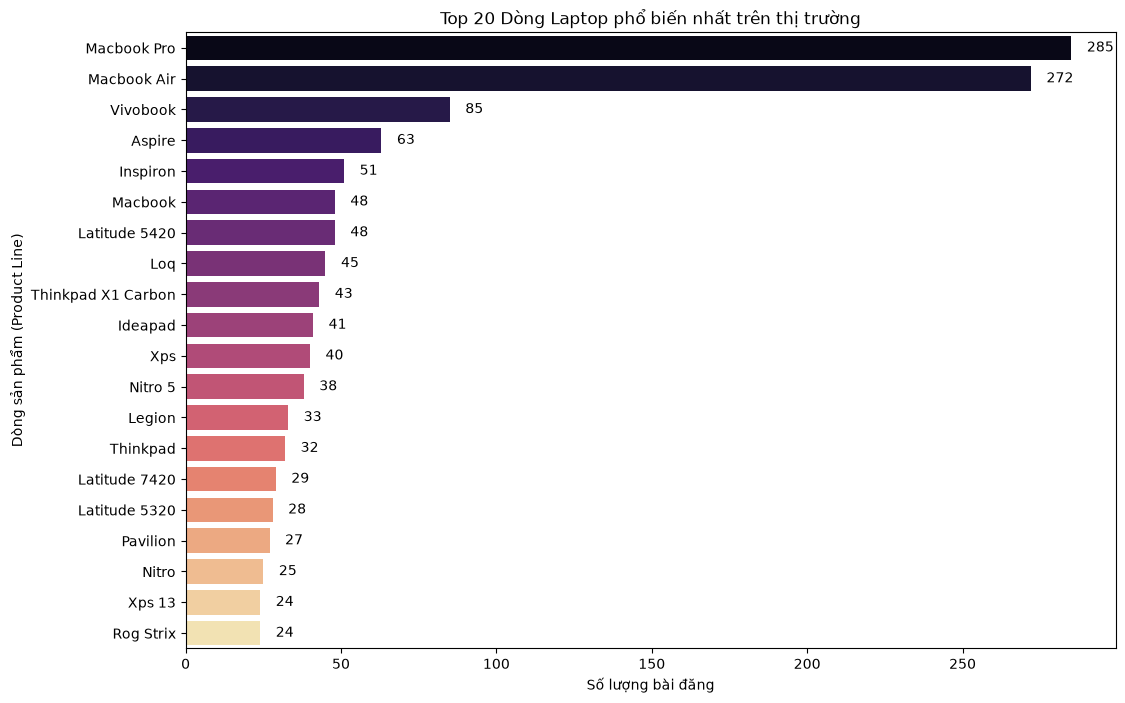

In [16]:
plt.figure(figsize=(12, 8))
valid_lines = df['product_line'].dropna().astype(str).str.strip().str.title()
top_20_lines = valid_lines.value_counts().head(20)
sns.barplot(x=top_20_lines.values, y=top_20_lines.index, palette='magma')
plt.title('Top 20 Dòng Laptop phổ biến nhất trên thị trường')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Dòng sản phẩm (Product Line)')

for i, v in enumerate(top_20_lines.values):
    plt.text(v + 5, i, str(v), color='black', va='center')

plt.show()

In [17]:
missing_lines = df['product_line'].isna().sum()
print(f"Số bài đăng không rõ dòng máy (Null): {missing_lines} ({missing_lines/len(df)*100:.1f}%)")
print(f"Tổng số dòng máy (Unique) phát hiện được: {df['product_line'].nunique()}")

Số bài đăng không rõ dòng máy (Null): 806 (21.8%)
Tổng số dòng máy (Unique) phát hiện được: 484


## CPU Vendor

In [18]:
df['cpu_vendor'].unique()

<StringArray>
[nan, 'intel', 'apple', 'amd']
Length: 4, dtype: str

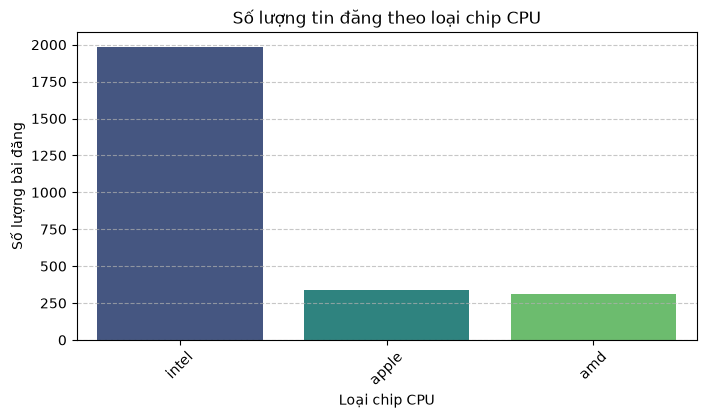

In [19]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df,
    x="cpu_vendor",
    order=df['cpu_vendor'].value_counts().index,
    palette="viridis"
)
plt.xlabel("Loại chip CPU")
plt.ylabel("Số lượng bài đăng")
plt.title("Số lượng tin đăng theo loại chip CPU")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [20]:
null_cpu_vendor = df['cpu_vendor'].isnull().sum()
print(f"Số lượng bài đăng không thu thập được loại chip CPU: {null_cpu_vendor}, chiếm {(null_cpu_vendor/df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng bài đăng không thu thập được loại chip CPU: 1060, chiếm 28.66% tổng số bài đăng


## CPU Model

### Dòng Intel

In [21]:
print(df[df['cpu_vendor'] == 'intel']['cpu_model'].unique())

<StringArray>
[   'i7 8650u',    'i7 8665u',    'i5 7200u',   'i5 10310u',   'i7-1185g7',
    'i7 8565u',    'i7 9850h',    'i5 10310',    'i5 8265u',   'i7 10850h',
 ...
     'i5 8265', 'ultra7 155h',     'i5 1235',    'i5-8400h', 'ultra 5 322',
    'i7 1050u',    'i5 5300u',   'i9 10885h',    'i5-8200y',     'i5-225u']
Length: 389, dtype: str


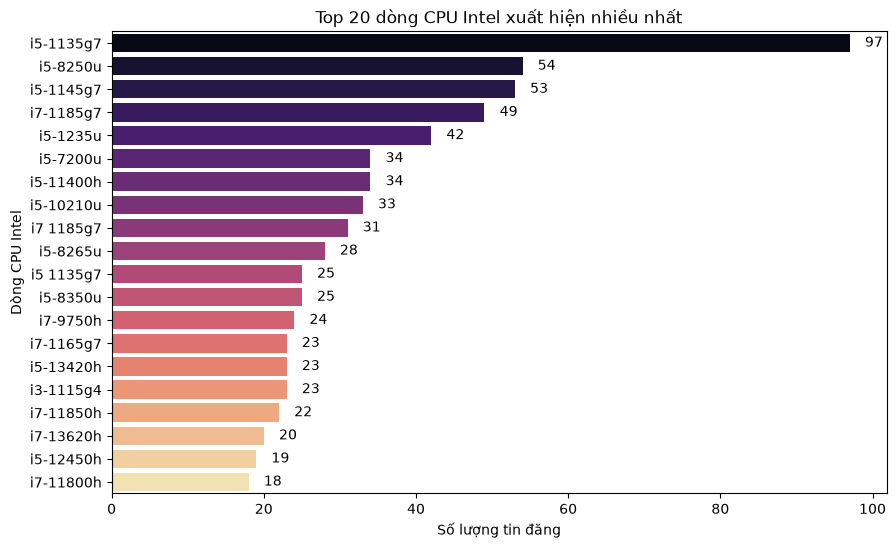

In [22]:
intel_chips = df[df['cpu_vendor'] == 'intel']['cpu_model'].value_counts()
intel_chips_top20 = intel_chips.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=intel_chips_top20.values, y=intel_chips_top20.index, palette='magma')
plt.title("Top 20 dòng CPU Intel xuất hiện nhiều nhất")
plt.xlabel("Số lượng tin đăng")
plt.ylabel("Dòng CPU Intel")

for i, v in enumerate(intel_chips_top20.values):
    plt.text(v + 2, i, str(v), color='black', va='center')

plt.show()

In [23]:
rare_intel_cpus = intel_chips[intel_chips < 5]
rare_pct = (len(rare_intel_cpus) / len(intel_chips)) * 100

print(f"Tổng số mã CPU Intel xuất hiện: {len(intel_chips)}")
print(f"Số lượng mã CPU Intel < 5 lần (hiếm): {len(rare_intel_cpus)}, chiếm {rare_pct:.2f}% toàn bộ mã Intel")

rare_listing_intel_pct = (rare_intel_cpus.sum() / intel_chips.sum()) * 100
print(f"Tỷ trọng bài đăng chứa CPU Intel hiếm: {rare_listing_intel_pct:.2f}%")

Tổng số mã CPU Intel xuất hiện: 389
Số lượng mã CPU Intel < 5 lần (hiếm): 276, chiếm 70.95% toàn bộ mã Intel
Tỷ trọng bài đăng chứa CPU Intel hiếm: 24.16%


In [24]:
noise_intel = intel_chips[intel_chips == 1].index.to_list()
print("Danh sách 20 mã CPU Intel cực hiếm:")
noise_intel[:20]

Danh sách 20 mã CPU Intel cực hiếm:


['i9 9880',
 'ultra 7-155u',
 'i510310u',
 'i5-3320',
 'i5 1245',
 'i5-8550u',
 'i7-10610',
 'core ultra 5 125u',
 'i5 6300u',
 'core ultra 5-125u',
 'i5-3337u',
 'i5-1250p',
 'i5-135u',
 'i5 540',
 'i9 13950hx',
 'i7-5500',
 'i5-1035g7',
 'i7 3630',
 'i5 8250',
 'i7 1195g7']

### Dòng AMD

In [25]:
print(df[df['cpu_vendor'] == 'amd']['cpu_model'].unique())

<StringArray>
[          'ryzen 7',     'ryzen 5 6600h',           'ryzen 5',
            'ryzen7',           'ryzen 3',     'ryzen 3 5425u',
     'ryzen 7 5700u',     'ryzen 3 3200u',    'ryzen 9 8940hx',
     'ryzen 5 5600h',     'ryzen 5 7520u',     'ryzen 5 5500u',
     'ryzen 7 4800h',     'ryzen 5 5600u',    'ryzen 9 8945hx',
    'ryzen 7 7735hs',     'ryzen 3 3250u',     'ryzen 5 4600h',
     'ryzen 5 7530u',     'ryzen 7 5800h',     'ryzen 5 7430u',
      'ryzen5 5600h',    'ryzen 7 7435hs',    'ryzen 5 7535hs',
    'ryzen 7 7840hs',     'ryzen 3 5300u',    'ryzen 9 6900hx',
 'ryzen 5 pro 2500u',     'ryzen 5 5625u',           'ryzen 9',
     'ryzen 7 6800u',     'ryzen 5 3500u',     'ryzen 7 6800h',
    'ryzen 5 7640hs',     'ryzen 7 3750h',     'ryzen 7 7730u',
    'ryzen 9 7945hx',    'ryzen 5 7533hs',     'ryzen 7 8840u',
     'ryzen 7 8745h',     'ryzen 7 5800u',    'ryzen 7 7745hs',
    'ryzen 7 6850hs',    'ryzen 9 8945hs',     'ryzen 5 2500u',
    'ryzen 9 9955hx',    '

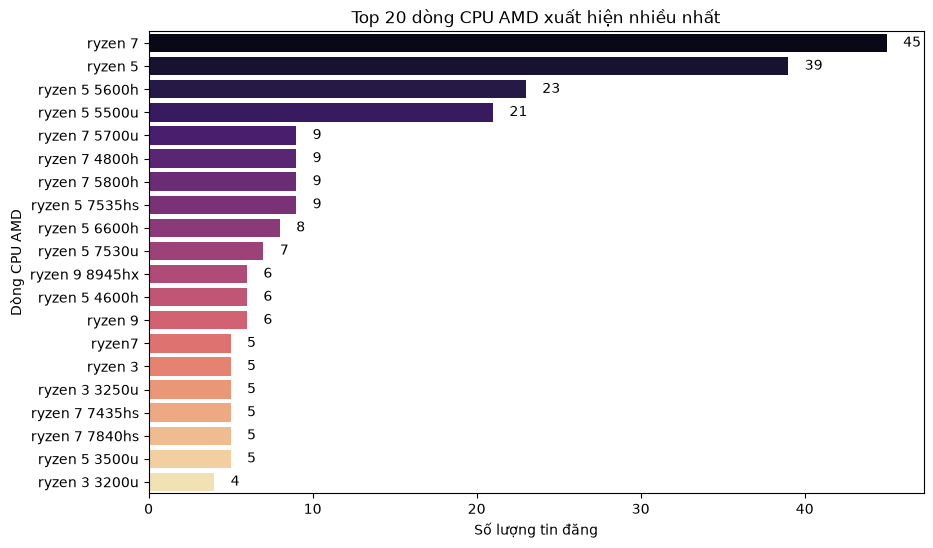

In [26]:
amd_chips = df[df['cpu_vendor'] == 'amd']['cpu_model'].value_counts()
amd_chips_top20 = amd_chips.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=amd_chips_top20.values, y=amd_chips_top20.index, palette='magma')
plt.title("Top 20 dòng CPU AMD xuất hiện nhiều nhất")
plt.xlabel("Số lượng tin đăng")
plt.ylabel("Dòng CPU AMD")

for i, v in enumerate(amd_chips_top20.values):
    plt.text(v + 1, i, str(v), color='black', va='center')

plt.show()

In [27]:
rare_amd_cpus = amd_chips[amd_chips < 5]
rare_pct = (len(rare_amd_cpus) / len(amd_chips)) * 100

print(f"Tổng số mã CPU AMD xuất hiện: {len(amd_chips)}")
print(f"Số lượng mã CPU AMD < 5 lần (hiếm): {len(rare_amd_cpus)}, chiếm {rare_pct:.2f}% toàn bộ mã amd")

rare_listing_amd_pct = (rare_amd_cpus.sum() / amd_chips.sum()) * 100
print(f"Tỷ trọng bài đăng chứa CPU AMD hiếm: {rare_listing_amd_pct:.2f}%")

Tổng số mã CPU AMD xuất hiện: 70
Số lượng mã CPU AMD < 5 lần (hiếm): 51, chiếm 72.86% toàn bộ mã amd
Tỷ trọng bài đăng chứa CPU AMD hiếm: 27.01%


In [28]:
noise_amd = amd_chips[amd_chips == 1].index.to_list()
print("Danh sách 20 mã CPU AMD cực hiếm:")
noise_amd[:20]

Danh sách 20 mã CPU AMD cực hiếm:


['ryzen 3 5425u',
 'ryzen 7 7735hs',
 'ryzen5 5600h',
 'ryzen 9 6900hx',
 'ryzen 5 pro 2500u',
 'ryzen 7 6800u',
 'ryzen 5 7640hs',
 'ryzen 5 7533hs',
 'ryzen 7 8840u',
 'ryzen 7 5800u',
 'ryzen 7 7745hs',
 'ryzen 7 6850hs',
 'ryzen 9 8945hs',
 'ryzen 5 2500u',
 'ryzen 9 9955hx',
 'ryzen 9 5900hs',
 'ryzen 7 4700u',
 'ryzen 5 3450u',
 'ryzen 5 4650u',
 'ryzen5 pro 4650u']

### Dòng Apple

In [29]:
print(df[df['cpu_vendor'] == 'apple']['cpu_model'].unique())

<StringArray>
['m4 pro',     'm2', 'm1 pro',     'm3', 'm3 pro',     'm4',     'm1',
 'm1 max', 'm2 pro', 'm2 max', 'm4 max']
Length: 11, dtype: str


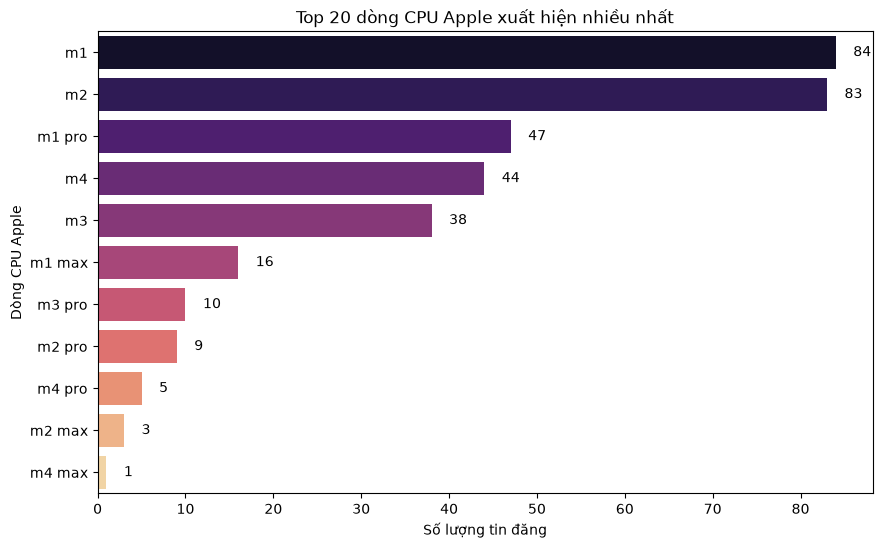

In [30]:
apple_chips = df[df['cpu_vendor'] == 'apple']['cpu_model'].value_counts()
apple_chips_top20 = apple_chips.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=apple_chips_top20.values, y=apple_chips_top20.index, palette='magma')
plt.title("Top 20 dòng CPU Apple xuất hiện nhiều nhất")
plt.xlabel("Số lượng tin đăng")
plt.ylabel("Dòng CPU Apple")

for i, v in enumerate(apple_chips_top20.values):
    plt.text(v + 2, i, str(v), color='black', va='center')

plt.show()

In [31]:
rare_apple_cpus = apple_chips[apple_chips < 5]
rare_pct = (len(rare_apple_cpus) / len(apple_chips)) * 100

print(f"Tổng số mã CPU Apple xuất hiện: {len(apple_chips)}")
print(f"Số lượng mã CPU Apple < 5 lần (hiếm): {len(rare_apple_cpus)}, chiếm {rare_pct:.2f}% toàn bộ mã Apple")

rare_listing_apple_pct = (rare_apple_cpus.sum() / apple_chips.sum()) * 100
print(f"Tỷ trọng bài đăng chứa CPU Apple hiếm: {rare_listing_apple_pct:.2f}%")

Tổng số mã CPU Apple xuất hiện: 11
Số lượng mã CPU Apple < 5 lần (hiếm): 2, chiếm 18.18% toàn bộ mã Apple
Tỷ trọng bài đăng chứa CPU Apple hiếm: 1.18%


In [32]:
noise_apple = apple_chips[apple_chips == 1].index.to_list()
print("Danh sách 20 mã CPU Apple cực hiếm:")
noise_apple[:20]

Danh sách 20 mã CPU Apple cực hiếm:


['m4 max']

## RAM (Random Access Memory)

In [33]:
df['raw_ram'].unique()

<StringArray>
[ '8 GB', '16 GB', '32 GB',     nan,  '4 GB',  '6 GB', '64 GB', '24 GB',
  '2 GB',  '7 GB', '12 GB',  'Khác', '48 GB', '10 GB', '20 GB', '36 GB',
 '18 GB',  '3 GB', '<1 GB']
Length: 19, dtype: str

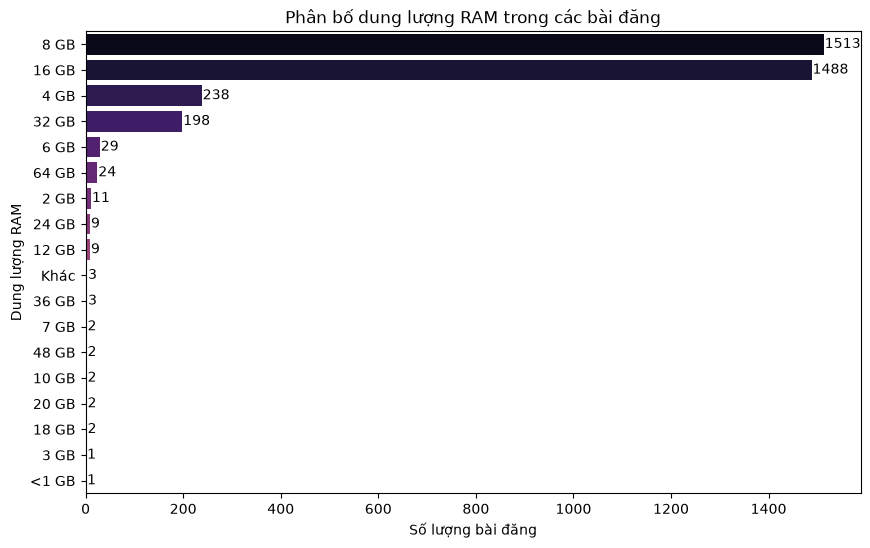

In [34]:
ram_counts = df['raw_ram'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=ram_counts.values, y=ram_counts.index, palette='magma')
plt.title("Phân bố dung lượng RAM trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Dung lượng RAM")

for i, v in enumerate(ram_counts):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [35]:
print(f"Số lượng bài đăng khuyết dữ liệu RAM: {df['raw_ram'].isnull().sum()}, chiếm {(df['raw_ram'].isnull().sum() / df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng bài đăng khuyết dữ liệu RAM: 161, chiếm 4.35% tổng số bài đăng


In [36]:
df[df['raw_ram'] == '2 GB']

,post_id,target_price,raw_cpu,raw_ram,raw_hard_drive,raw_hard_drive_type,pc_brand,pc_cpu,pc_ram,laptop_screen_size,...,battery_condition,warranty_months,warranty_type,has_warranty,is_upgraded,repair_status,year_production,year_purchase,bundles,has_bundle
443,135555220,2000000.0,Intel Core i3,2 GB,NaN,HDD,6,6.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
758,135194485,1000000.0,Intel Core i3,2 GB,500 GB,HDD,4,6.0,3.0,5.0,...,NaN,NaN,cua_hang,1,NaN,NaN,NaN,NaN,luôn combo bàn phím rời màu trắng + chuột có d...,1
1079,135560398,600000.0,Intel Core 2 Duo,2 GB,250 GB,SSD,12,4.0,3.0,NaN,...,NaN,NaN,NaN,0,1.0,original,NaN,NaN,NaN,0
1095,135565584,550000.0,Khác,2 GB,NaN,NaN,4,10.0,3.0,5.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
1381,135306968,550000.0,Intel Pentium,2 GB,< 128 GB,HDD,1,9.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2119,135445065,500000.0,Intel Pentium,2 GB,500 GB,HDD,5,9.0,3.0,4.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2324,135561491,800000.0,Intel Celeron,2 GB,500 GB,HDD,7,3.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2802,135456520,500000.0,Intel Pentium,2 GB,NaN,NaN,11,9.0,3.0,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2835,135462065,800000.0,Intel Atom,2 GB,< 128 GB,SSD,12,2.0,3.0,2.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,sạc,1
2960,135566611,800000.0,Intel Celeron,2 GB,< 128 GB,SSD,6,3.0,3.0,3.0,...,NaN,NaN,NaN,0,NaN,original,2015.0,NaN,NaN,0


In [37]:
df[df['raw_ram'] == "<1 GB"]

,post_id,target_price,raw_cpu,raw_ram,raw_hard_drive,raw_hard_drive_type,pc_brand,pc_cpu,pc_ram,laptop_screen_size,...,battery_condition,warranty_months,warranty_type,has_warranty,is_upgraded,repair_status,year_production,year_purchase,bundles,has_bundle
2845,135465228,200000.0,Khác,<1 GB,< 128 GB,HDD,5,10.0,1.0,5.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0


## Hard Drive (Ổ cứng)

### Type of Hard Drive (Phân loại ổ cứng)

In [38]:
df['raw_hard_drive_type'].unique()

<StringArray>
['SSD', nan, 'HDD']
Length: 3, dtype: str

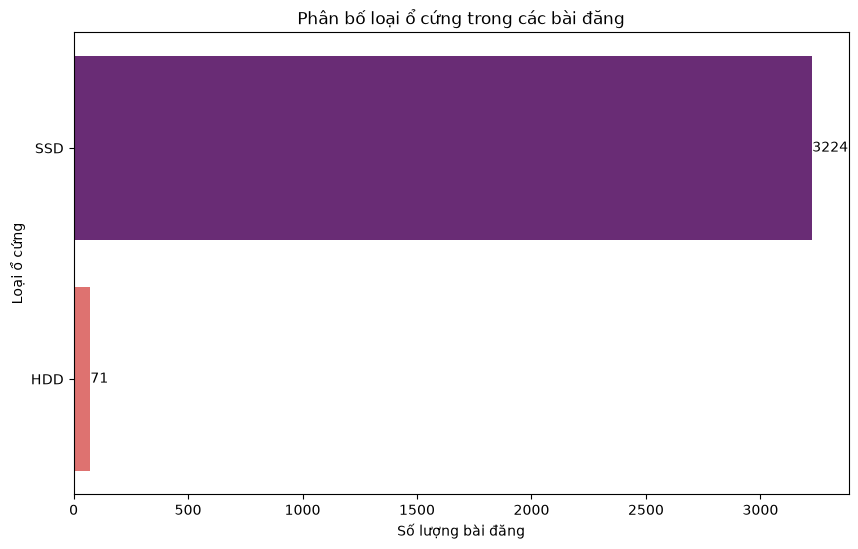

In [39]:
hard_drive_type = df['raw_hard_drive_type'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=hard_drive_type.values, y=hard_drive_type.index, palette='magma')
plt.title("Phân bố loại ổ cứng trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Loại ổ cứng")

for i, v in enumerate(hard_drive_type):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [40]:
print(f"Số lượng bài đăng khuyết dữ liệu phân loại ổ cứng: {df['raw_hard_drive_type'].isnull().sum()}, chiếm {(df['raw_hard_drive_type'].isnull().sum() / df.shape[0])*100:.2f}%")

Số lượng bài đăng khuyết dữ liệu phân loại ổ cứng: 403, chiếm 10.90%


### Dung lượng ổ cứng

In [41]:
df['raw_hard_drive'].unique()

<StringArray>
[  '256 GB',   '512 GB',       '13',   '250 GB',   '128 GB',   '750 GB',
   '640 GB',     '1 TB', '< 128 GB',   '320 GB',   '500 GB',     '2 TB',
        nan,     'Khác',   '480 GB',     '3 TB']
Length: 16, dtype: str

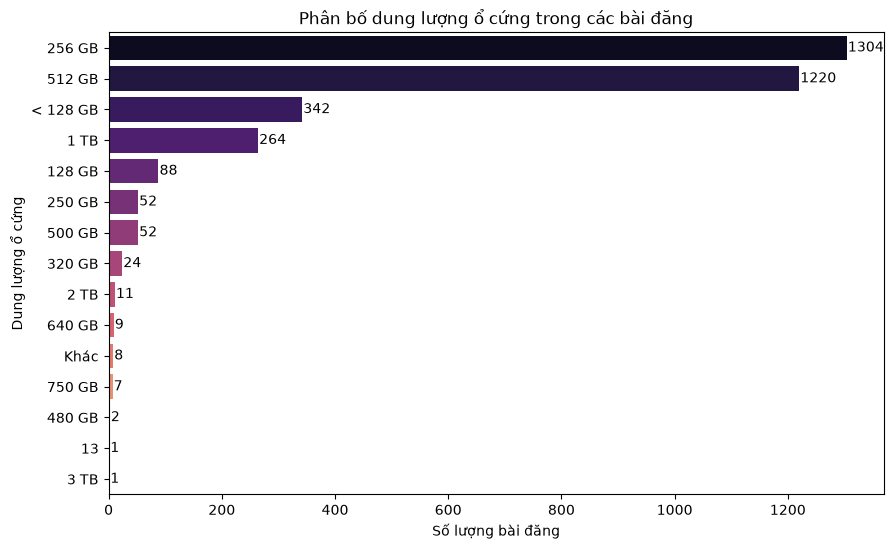

In [42]:
storage_hd = df['raw_hard_drive'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=storage_hd.values, y=storage_hd.index, palette='magma')
plt.title("Phân bố dung lượng ổ cứng trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Dung lượng ổ cứng")

for i, v in enumerate(storage_hd):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [43]:
print(f"Số lượng bài đăng khuyết dữ liệu dung lượng ổ cứng: {df['raw_hard_drive'].isnull().sum()}, chiếm {(df['raw_hard_drive'].isnull().sum() / df.shape[0])*100:.2f}%")

Số lượng bài đăng khuyết dữ liệu dung lượng ổ cứng: 313, chiếm 8.46%


## GPU (Graphic Process Unit)

### GPU Type (Loại GPU)

In [44]:
df['gpu_type'].unique()

<StringArray>
['integrated', nan, 'discrete']
Length: 3, dtype: str

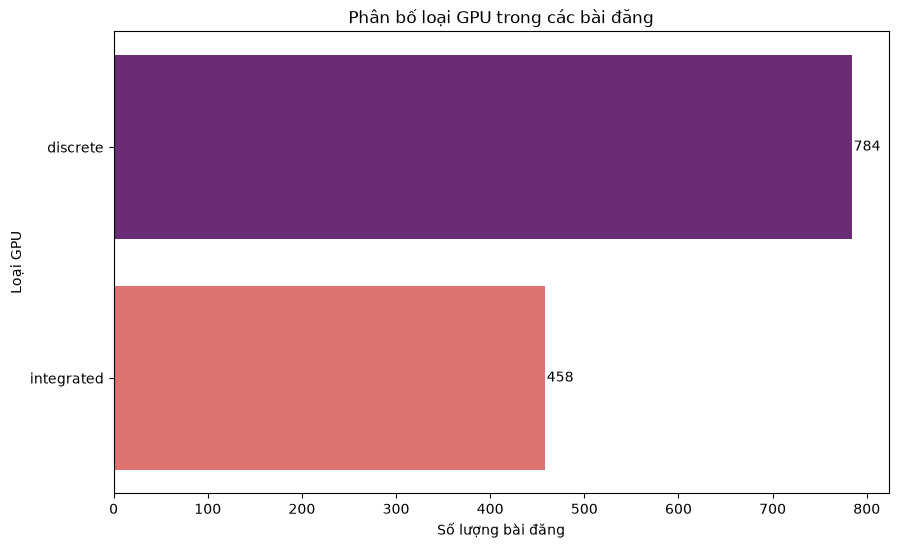

In [45]:
gpu_type = df['gpu_type'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=gpu_type.values, y=gpu_type.index, palette='magma')
plt.title("Phân bố loại GPU trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Loại GPU")

for i, v in enumerate(gpu_type):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()


In [46]:
print(f"Số lượng bài đăng khuyết dữ liệu loại GPU: {df['gpu_type'].isnull().sum()}, chiếm {(df['gpu_type'].isnull().sum() / df.shape[0])*100:.2f}% tổng số bài đăng")

Số lượng bài đăng khuyết dữ liệu loại GPU: 2456, chiếm 66.41% tổng số bài đăng


### GPU Model

In [47]:
df['gpu_model'].unique()

<StringArray>
[     'intel hd graphics',               'intel hd',                      nan,
                    'uhd',                 'mx 130',            'quadro p620',
           'quadro t1000',                'iris xe',               'rtx 3000',
 'intel hd graphics 4600',
 ...
  'intel hd graphics 400',               'gtx 970m',              'rtx a4000',
             'm4600 core',                 'mx 940',                'gtx 970',
        'radeon rx 6550m',               'gtx 2050',                'gtx 850',
            'rtx 1650 ti']
Length: 138, dtype: str

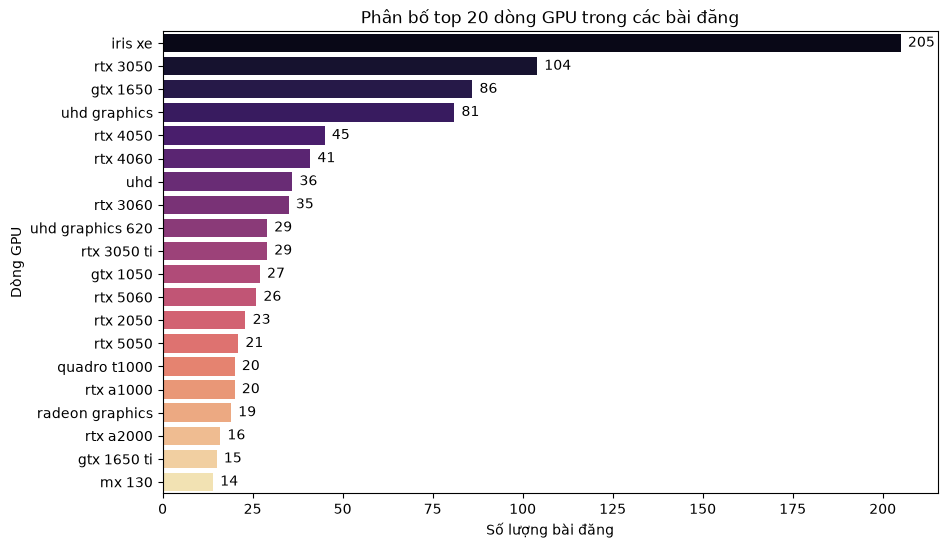

In [48]:
gpu_model = df['gpu_model'].value_counts()
gpu_model_top20 = gpu_model.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=gpu_model_top20.values, y=gpu_model_top20.index, palette='magma')
plt.title("Phân bố top 20 dòng GPU trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Dòng GPU")

for i, v in enumerate(gpu_model_top20):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [49]:
rare_gpu_model = gpu_model[gpu_model < 5]
rare_gpu_pct = (len(rare_gpu_model) / len(gpu_model)) * 100

print(f"Tổng số mã CPU duy nhất: {len(gpu_model)}")
print(f"Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): {len(rare_gpu_model)} ({rare_gpu_pct:.1f}% tổng số mã)")

Tổng số mã CPU duy nhất: 137
Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): 97 (70.8% tổng số mã)


In [50]:
rare_listings_gpu_pct = (rare_gpu_model.sum() / len(df.dropna(subset=['gpu_model']))) * 100
print(f"Tỷ trọng bài đăng chứa GPU hiếm: {rare_listings_gpu_pct:.2f}%")

Tỷ trọng bài đăng chứa GPU hiếm: 13.20%


In [51]:
print(f"Số bài đăng khuyết dữ liệu dung lượng VRAM GPU: {df['gpu_model'].isnull().sum()}, chiếm {(df['gpu_model'].isnull().sum() / df.shape[0])*100:.2f}% tổng số bài đăng")

Số bài đăng khuyết dữ liệu dung lượng VRAM GPU: 2456, chiếm 66.41% tổng số bài đăng


## Screen (Màn hình)

### Screen size (Kích thước màn hình)

In [52]:
df['screen_size_inch'].unique()

array([15.6, 14. , 13.3,  nan, 17.3, 16. , 17. , 15. , 13.5, 13. , 12.5,
       11. , 12.4, 13.6, 15.3, 12.3, 14.5, 12. , 10.5, 14.4, 12.1, 13.4,
       15.4, 10. , 15.1, 14.2, 14.1, 11.6, 15.5, 10.1], dtype=float32)

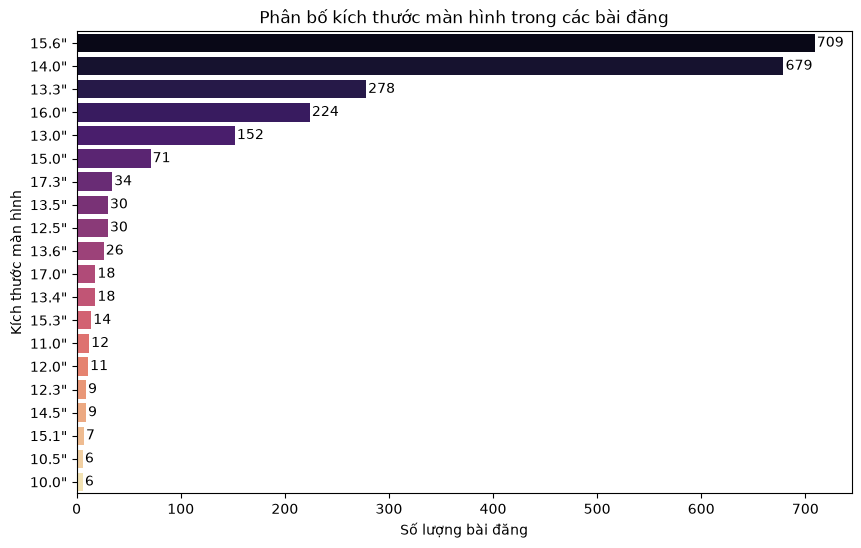

In [53]:
screen_size = df['screen_size_inch'].value_counts()
screen_size_top20 = screen_size.head(20)
clean_labels = screen_size_top20.index.to_series().round(1).astype(str) + '"'

plt.figure(figsize=(10, 6))
sns.barplot(x=screen_size_top20.values, y=clean_labels, palette='magma')
plt.title("Phân bố kích thước màn hình trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Kích thước màn hình")

for i, v in enumerate(screen_size_top20):
    plt.text(v + 2, i, str(v), color='black', va='center')
plt.show()

In [54]:
null_screen_size = df['screen_size_inch'].isnull().sum()
print(f"Số bài đăng khuyết kích thước màn hình: {null_screen_size}, chiếm {(null_screen_size / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết kích thước màn hình: 1325, chiếm 35.83% tổng bài đăng


### Resolution (Độ phân giải)

In [55]:
df['resolution'].unique()

<StringArray>
[nan, 'fhd', 'fhd+', '4k/uhd', 'qhd+', 'retina', '3k', '2k/qhd']
Length: 8, dtype: str

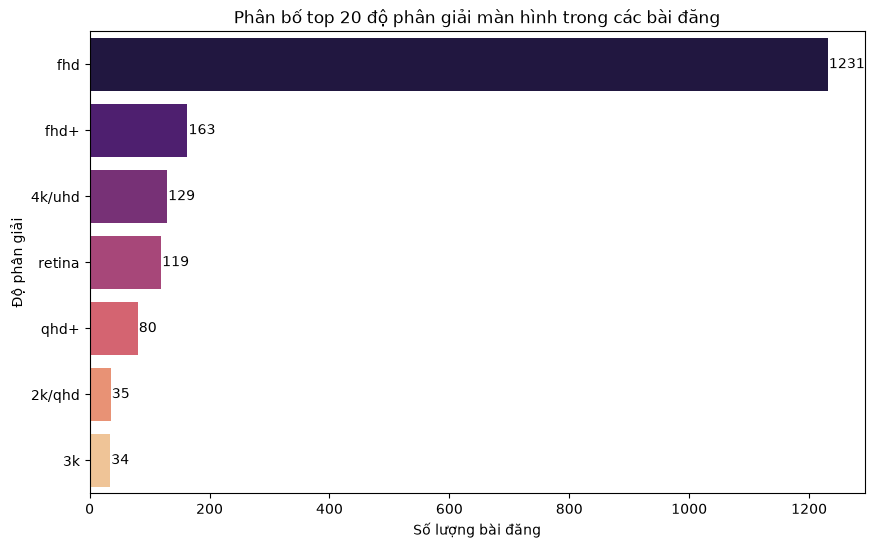

In [56]:
resolution = df['resolution'].value_counts()
resolution_top20 = resolution.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=resolution_top20.values, y=resolution_top20.index, palette='magma')
plt.title("Phân bố top 20 độ phân giải màn hình trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Độ phân giải")

for i, v in enumerate(resolution_top20):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [57]:
rare_resolution = resolution[resolution < 5]
rare_resolution_pct = (len(rare_resolution) / len(resolution)) * 100

print(f"Tổng số mã CPU duy nhất: {len(resolution)}")
print(f"Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): {len(rare_resolution)} ({rare_resolution_pct:.1f}% tổng số mã)")

Tổng số mã CPU duy nhất: 7
Số lượng mã CPU xuất hiện < 5 lần (Mã hiếm): 0 (0.0% tổng số mã)


In [58]:
rare_listings_resolution_pct = (rare_resolution.sum() / len(df.dropna(subset=['resolution']))) * 100
print(f"Tỷ trọng bài đăng chứa CPU hiếm: {rare_listings_resolution_pct:.2f}%")

Tỷ trọng bài đăng chứa CPU hiếm: 0.00%


In [59]:
null_resolution = df['resolution'].isnull().sum()
print(f"Tổng số bài đăng khuyết độ phân giải màn hình: {null_screen_size}, chiếm tỷ lệ {(null_resolution / df.shape[0])*100:.2f}% tổng số bài đăng")

Tổng số bài đăng khuyết độ phân giải màn hình: 1325, chiếm tỷ lệ 51.57% tổng số bài đăng


### Torch sensitive (Màn hình cảm ứng)

In [60]:
df['touch_sensitive'].unique()

array([nan,  1.,  0.])

In [61]:
df['touch_sensitive'] = df['touch_sensitive'].fillna(0).astype(int)
touch_sensitive = df['touch_sensitive'].value_counts()

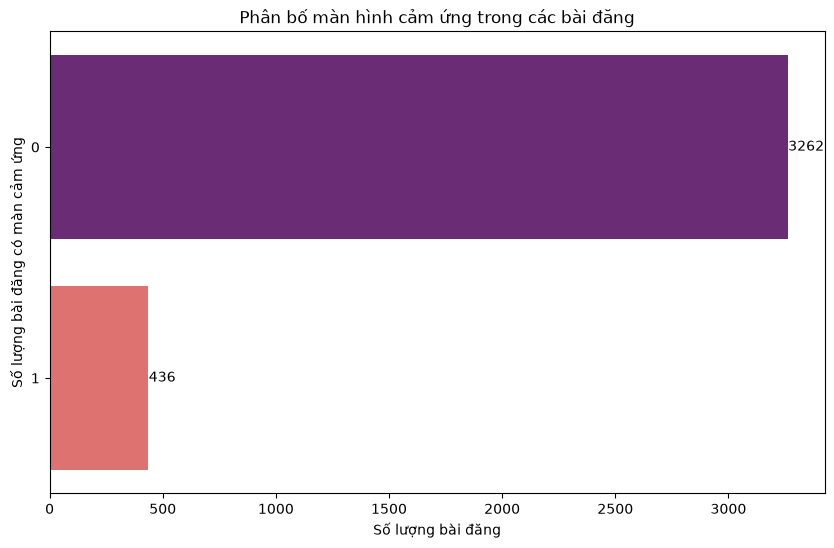

In [62]:
plt.figure(figsize=(10, 6))
sns.barplot(x=touch_sensitive.values, y=touch_sensitive.index.astype(str), palette='magma')
plt.title("Phân bố màn hình cảm ứng trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Số lượng bài đăng có màn cảm ứng")

for i, v in enumerate(touch_sensitive):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

## Battery

### Battery Condition (Tình trạng pin dạng chữ được trích xuất)

In [63]:
df['battery_condition'].unique()

<StringArray>
[nan, 'good', 'worn', 'replaced']
Length: 4, dtype: str

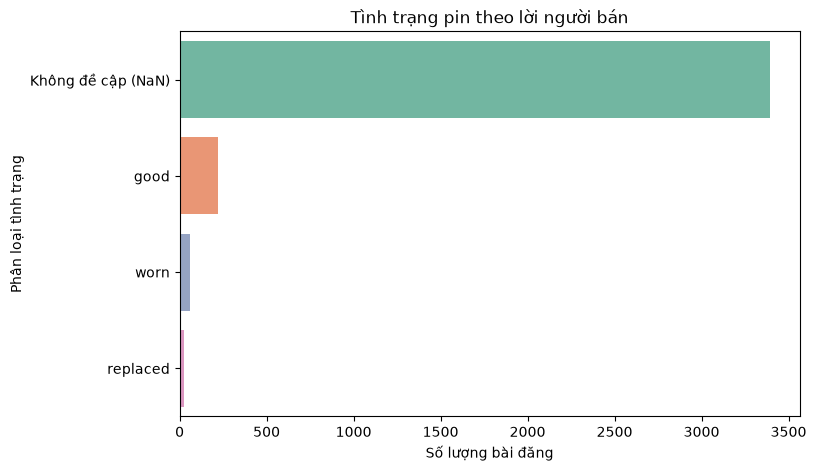

In [64]:
plt.figure(figsize=(8, 5))
cond_counts = df['battery_condition'].fillna('Không đề cập (NaN)').value_counts()
sns.barplot(x=cond_counts.values, y=cond_counts.index, palette='Set2')
plt.title('Tình trạng pin theo lời người bán')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Phân loại tình trạng')
plt.show()

In [65]:
null_battery_cond = df['battery_condition'].isnull().sum()
print(f"Số bài đăng khuyết thông tin tình trạng pin từ văn bản {null_battery_cond} ,chiếm {(null_battery_cond / df.shape[0])*100:.2f}% tổng số bài đăng" )

Số bài đăng khuyết thông tin tình trạng pin từ văn bản 3394 ,chiếm 91.78% tổng số bài đăng


### Battery cycles (Chu kỳ sạc)

In [66]:
df['battery_cycles'].unique()

array([ nan, 390.,  10.,   3., 216.,  20., 189., 152.,  99.,  40.,   5.,
        72.])

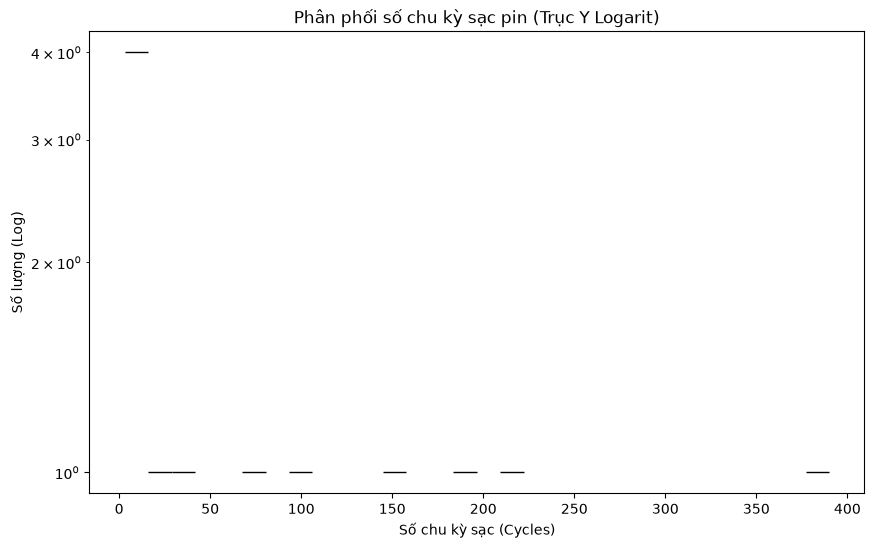

In [67]:
plt.figure(figsize=(10, 6))
valid_cycles = df['battery_cycles'].dropna()
sns.histplot(valid_cycles, bins=30, color='blue', log_scale=(False, True))
plt.title('Phân phối số chu kỳ sạc pin (Trục Y Logarit)')
plt.xlabel('Số chu kỳ sạc (Cycles)')
plt.ylabel('Số lượng (Log)')
plt.show()

In [68]:
null_battery_cycles = df['battery_cycles'].isnull().sum()
print(f"Số bài đăng khuyết dữ liệu chu kỳ sạc: {null_battery_cycles}, chiếm {(null_battery_cycles / df.shape[0])*100:.2f}% tổng số bài đăng")

Số bài đăng khuyết dữ liệu chu kỳ sạc: 3686, chiếm 99.68% tổng số bài đăng


### Battery hours (Tổng số giờ sạc)

In [69]:
df['battery_hours'].unique()

array([ 4. ,  nan,  5. ,  3. ,  6. ,  8. ,  2. ,  2.3,  1. , 16. ,  2.5,
        4.5,  1.5,  3.5], dtype=float32)

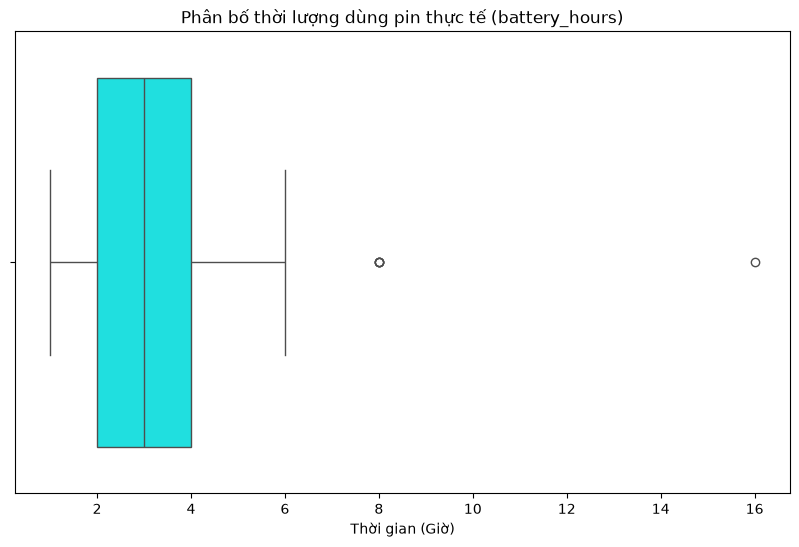

In [70]:
plt.figure(figsize=(10, 6))
valid_hours = df['battery_hours'].dropna()
sns.boxplot(x=valid_hours, color='cyan')
plt.title('Phân bố thời lượng dùng pin thực tế (battery_hours)')
plt.xlabel('Thời gian (Giờ)')
plt.show()

In [71]:
fake_battery = df[df['battery_hours'] > 15]
print(f"Số lượng máy có pin vô lý (> 15 tiếng): {len(fake_battery)}")

Số lượng máy có pin vô lý (> 15 tiếng): 1


In [72]:
null_battery_hours = df['battery_hours'].isnull().sum()
print(f"Số bài đăng khuyết thời gian sử dụng: {null_battery_cycles}, chiếm {(null_battery_cycles / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết thời gian sử dụng: 3686, chiếm 99.68% tổng bài đăng


### Battery percentage (% độ chai pin)

In [73]:
df['battery_pct'].unique()

array([ nan, 100.,  84.,  92.,  86.,  94.,  98.,  72.,  99.,  93.,  88.,
        95.,  87.,  74.,  83.,  85.,  97.,  79.,  62.,  80.,  89.,  82.,
        96.,  91.,  81.,  90.,  78.,  77.,  75.,  60.])

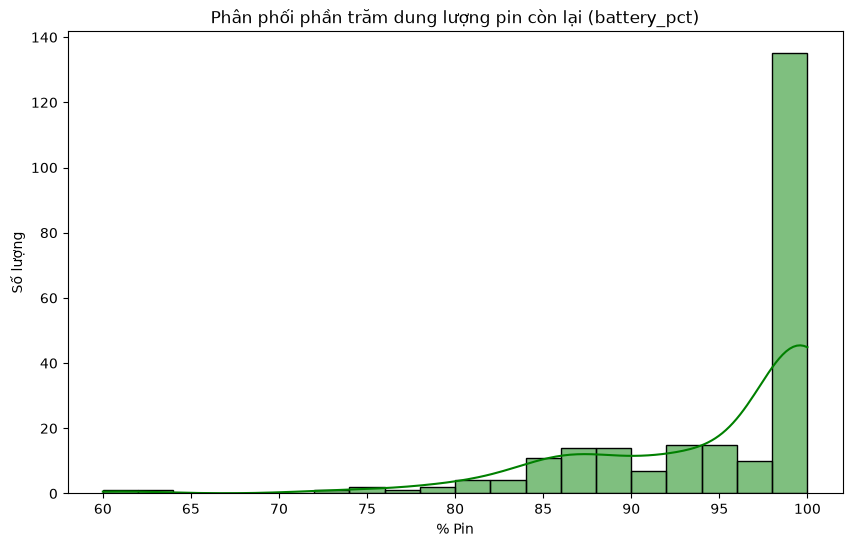

In [74]:
plt.figure(figsize=(10, 6))
valid_pct = df['battery_pct'].dropna()
sns.histplot(valid_pct, bins=20, kde=True, color='green')
plt.title('Phân phối phần trăm dung lượng pin còn lại (battery_pct)')
plt.xlabel('% Pin')
plt.ylabel('Số lượng')
plt.show()

In [75]:
pct_100 = (valid_pct == 100).sum()
print(f"Số bài đăng báo pin 100%: {pct_100} ({pct_100/len(valid_pct)*100:.2f}%)")

Số bài đăng báo pin 100%: 109 (45.99%)


In [76]:
null_battery_pct = df['battery_pct'].isnull().sum()
print(f"Số bài đăng khuyết dữ liệu về % pin: {null_battery_pct}, chiếm {(null_battery_pct / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết dữ liệu về % pin: 3461, chiếm 93.59% tổng bài đăng


## Condition (Độ mới ngoại hình máy trích xuất từ văn bản)

### New Seal (Máy mới 100% chưa kích hoạt)

In [77]:
df['is_new_seal'].unique()

array([nan,  1.])

In [78]:
new_seal = df['is_new_seal'].value_counts()
print(f"Số lượng bài đăng bán máy new seal: {new_seal.values}")

Số lượng bài đăng bán máy new seal: [43]


### Like new (Máy có ngoại hình 99%/Like new)

In [79]:
df['is_like_new'].unique()

array([nan,  1.])

In [80]:
like_new = df['is_like_new'].value_counts()
print(f"Số lượng bài đăng bán máy like new: {like_new.values}")

Số lượng bài đăng bán máy like new: [431]


### Tỷ lệ độ mới trích xuất từ văn bản

In [81]:
df['condition_pct'].unique()

array([ nan,  99.,  95.,  98.,  97.,  96., 100.,  90.,  94.,  80.])

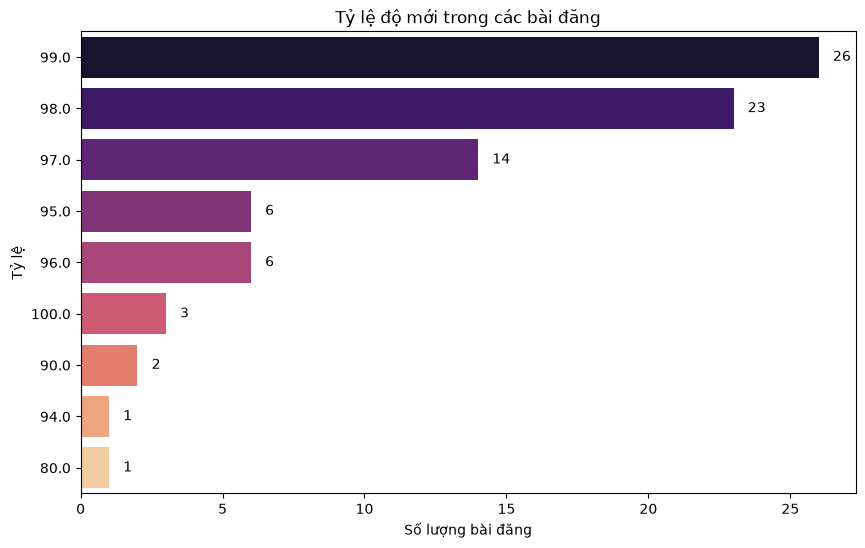

In [82]:
condition_pct = df['condition_pct'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=condition_pct.values, y=condition_pct.index.astype(str), palette='magma')
plt.title("Tỷ lệ độ mới trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Tỷ lệ")

for i, v in enumerate(condition_pct):
    plt.text(v + 0.5, i, str(v), color='black', va='center')
    
plt.show()

In [83]:
null_condition_pct = df['condition_pct'].isnull().sum()
print(f"Các bài đăng khuyết tỷ lệ mới của máy: {null_condition_pct}, chiếm {(null_condition_pct / df.shape[0])*100:.2f}% tổng số bài đăng")

Các bài đăng khuyết tỷ lệ mới của máy: 3616, chiếm 97.78% tổng số bài đăng


### Repair status (Tình trạng sửa chữa của máy)

In [84]:
df['repair_status'].unique()

<StringArray>
['original', nan, 'repaired']
Length: 3, dtype: str

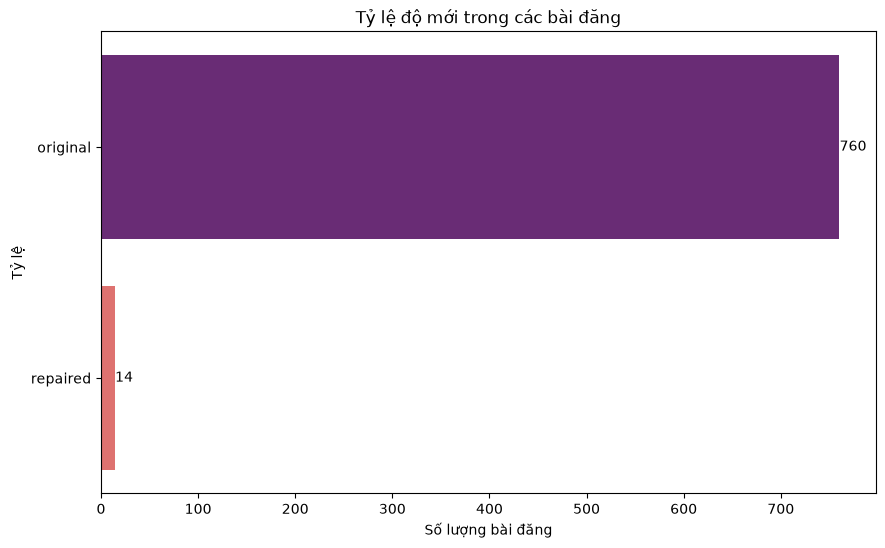

In [85]:
repair_status = df['repair_status'].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=repair_status.values, y=repair_status.index, palette='magma')
plt.title("Tỷ lệ độ mới trong các bài đăng")
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Tỷ lệ")

for i, v in enumerate(repair_status):
    plt.text(v + 0.5, i, str(v), color='black', va='center')
    
plt.show()

In [86]:
null_repair_status = df["repair_status"].isnull().sum()
print(f"Số bài đăng khuyết tình trạng sửa chữa: {null_repair_status}, chiếm {(null_repair_status / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết tình trạng sửa chữa: 2924, chiếm 79.07% tổng bài đăng


## Seller rating & Region (Thông tin người bán và địa phương)

### Seller rating

In [87]:
df['seller_rating'].unique()

array([4.8, 4.9, 4.4, 5. , nan, 4.7, 4.5, 4.6, 3.4, 4. , 3.7, 3. , 4.1,
       4.3, 2.6, 3.8, 4.2, 1. , 3.9, 2. , 3.6, 2.5, 2.9, 3.3, 3.1, 2.8,
       2.3, 3.5], dtype=float32)

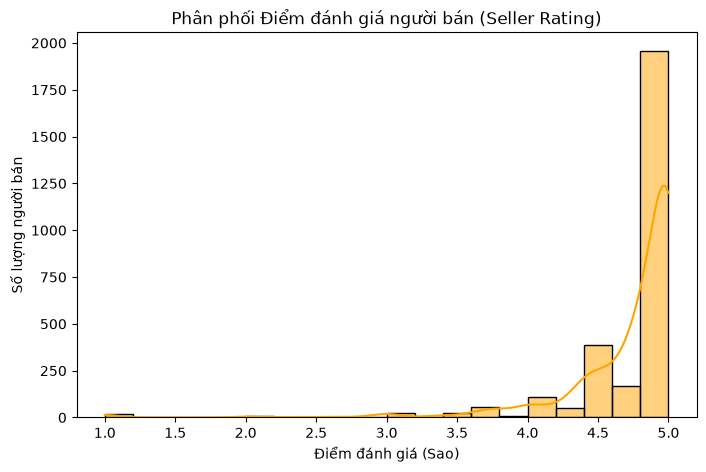

In [88]:
plt.figure(figsize=(8, 5))
valid_ratings = df[df['seller_rating'] > 0]['seller_rating']
sns.histplot(valid_ratings, bins=20, kde=True, color='orange')
plt.title('Phân phối Điểm đánh giá người bán (Seller Rating)')
plt.xlabel('Điểm đánh giá (Sao)')
plt.ylabel('Số lượng người bán')
plt.show()

In [89]:
bins = [-1, 5, 50, float('inf')]
labels = ['(0-5)', '(6-50)', '(>50)']
df['seller_type_eda'] = pd.cut(df['seller_sold_count'], bins=bins, labels=labels)
print("\nPhân loại người bán theo số lượng đã bán:")
print(df['seller_type_eda'].value_counts())


Phân loại người bán theo số lượng đã bán:
seller_type_eda
(>50)     1776
(6-50)    1071
(0-5)      851
Name: count, dtype: int64


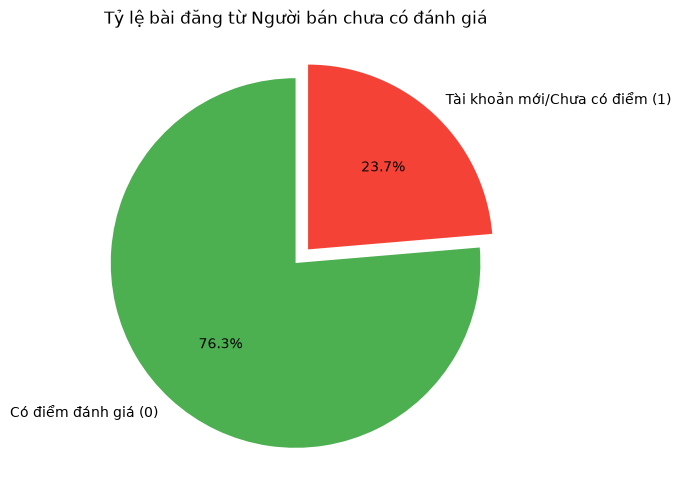

In [90]:
plt.figure(figsize=(6, 6))

missing_counts = df['is_seller_rating_missing'].value_counts()
labels = ['Có điểm đánh giá (0)', 'Tài khoản mới/Chưa có điểm (1)']

plt.pie(missing_counts, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#4CAF50', '#F44336'], explode=(0, 0.1))
plt.title('Tỷ lệ bài đăng từ Người bán chưa có đánh giá')
plt.show()

### Region (Khu vực)

In [91]:
df['region_name'].unique()

<StringArray>
[     'TP Hà Nội', 'TP Hồ Chí Minh',      'Vĩnh Long',     'TP Đà Nẵng',
     'TP Cần Thơ',       'Bắc Ninh',   'TP Hải Phòng',        'Đắk Lắk',
         'TP Huế',       'Đồng Nai',       'Tây Ninh',        'Gia Lai',
    'Tuyên Quang',      'Đồng Tháp',      'Khánh Hòa',       'An Giang',
       'Lâm Đồng',       'Hưng Yên',        'Nghệ An',      'Ninh Bình',
     'Quảng Ninh',      'Thanh Hóa',        'Phú Thọ',      'Quảng Trị',
        'Lào Cai',         'Cà Mau',       'Lạng Sơn',         'Sơn La',
    'Thái Nguyên',     'Quảng Ngãi',        'Hà Tĩnh']
Length: 31, dtype: str

In [92]:
df['ward_name'].unique()

<StringArray>
[  'Phường Phú Diễn',   'Phường Tân Hưng',    'Phường Đống Đa',
  'Phường Diên Hồng',  'Phường Việt Hưng',   'Phường Hòa Hưng',
    'Phường Hà Đông',         'Xã Trà Ôn',  'Phường Định Công',
   'Phường Hải Châu',
 ...
      'Xã Xuân Lãng',       'Xã An Phước',       'Xã Thạch Hà',
     'Xã Giồng Trôm',      'Xã Diên Điền',      'Xã Ngãi Giao',
       'Xã Nhơn Hội',      'Xã Lộc Thuận', 'Xã Phước Vĩnh Tây',
       'Xã Đông Anh']
Length: 359, dtype: str

In [93]:
region_counts = df['region_name'].value_counts(dropna=False)
region_pct = (region_counts / df.shape[0]) * 100
print("Top 5 khu vực chiếm tỷ trọng lớn nhất:")
region_pct.head(5)

Top 5 khu vực chiếm tỷ trọng lớn nhất:


region_name
TP Hồ Chí Minh    57.030827
TP Hà Nội         19.632234
TP Đà Nẵng         7.598702
TP Cần Thơ         5.273121
Đắk Lắk            1.270957
Name: count, dtype: float64

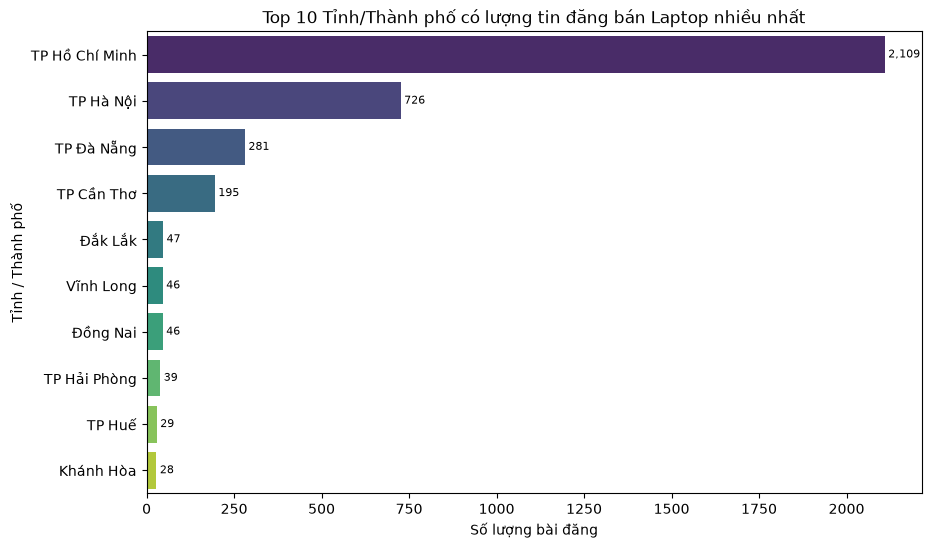

In [94]:
plt.figure(figsize=(10, 6))
sns.barplot(x=region_counts.head(10).values, y=region_counts.head(10).index.astype(str), palette='viridis', orient='h')
plt.title('Top 10 Tỉnh/Thành phố có lượng tin đăng bán Laptop nhiều nhất')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Tỉnh / Thành phố')

for i, v in enumerate(region_counts.head(10).values):
    plt.text(v + 10, i, f"{v:,.0f}", color='black', va='center', fontsize=8)

plt.show()

In [95]:
unique_wards = df['ward_name'].nunique()
print(f"Tổng số Phường/Xã duy nhất trong tập dữ liệu: {unique_wards}")

Tổng số Phường/Xã duy nhất trong tập dữ liệu: 359


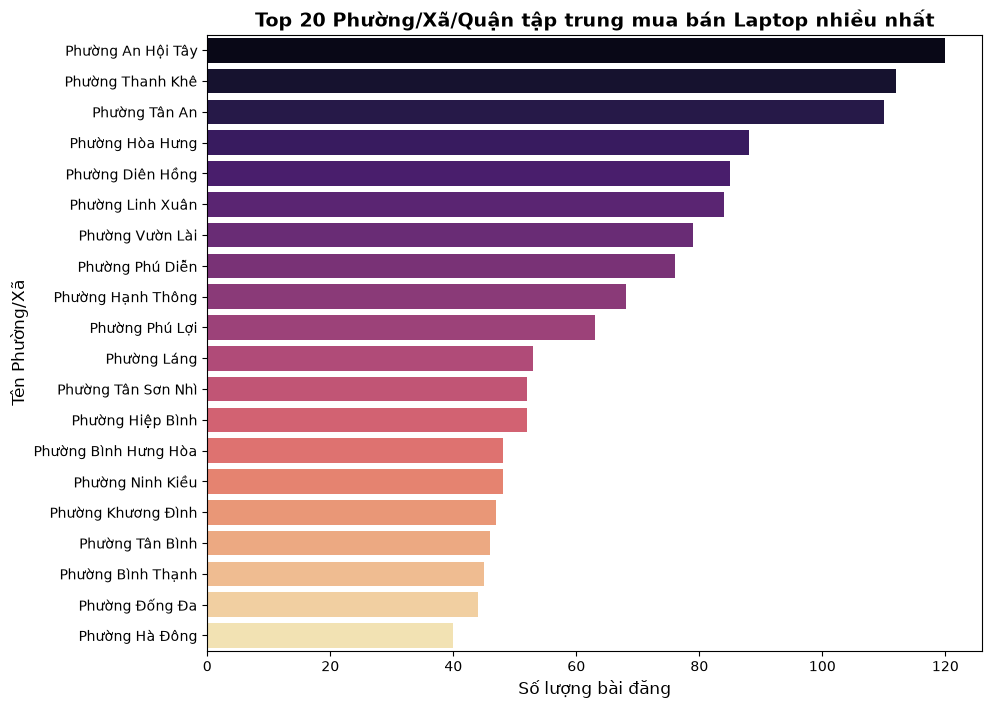

In [96]:
ward_counts = df['ward_name'].value_counts(dropna=False).head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=ward_counts.values, y=ward_counts.index.astype(str), palette='magma', orient='h')
plt.title('Top 20 Phường/Xã/Quận tập trung mua bán Laptop nhiều nhất', fontsize=14, fontweight='bold')
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Tên Phường/Xã', fontsize=12)
plt.show()

## Origin (Nguồn gốc/Xuất xứ)

### Origin type (Loại nguồn gốc)

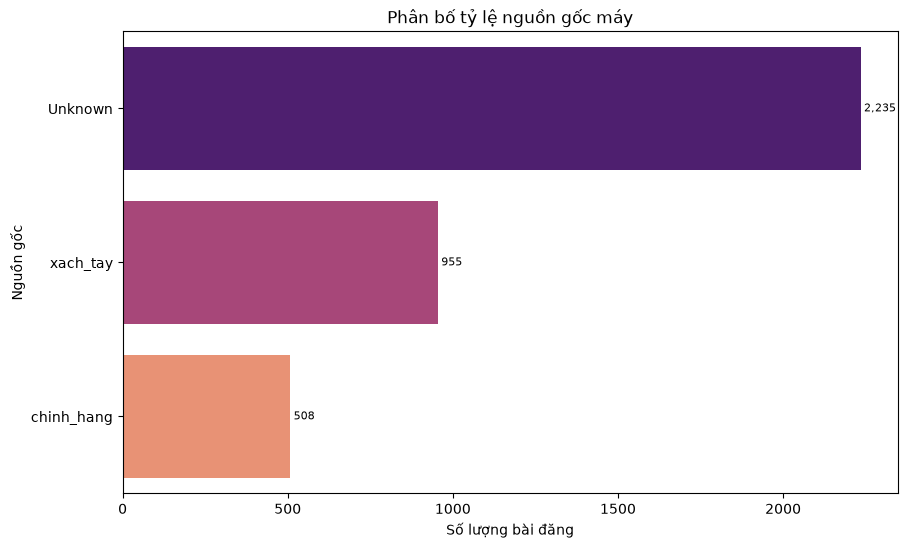

In [97]:
plt.figure(figsize=(10, 6))
origin_counts = df['origin_type'].fillna('Unknown').value_counts()
sns.barplot(x=origin_counts.values, y=origin_counts.index, palette='magma')
plt.xlabel("Số lượng bài đăng")
plt.ylabel("Nguồn gốc")
plt.title("Phân bố tỷ lệ nguồn gốc máy")

for i, v in enumerate(origin_counts):
    plt.text(v + 10, i, f"{v:,.0f}", color='black', va='center', fontsize=8)
    
plt.show()

In [98]:
null_origin_type = df['origin_type'].isnull().sum()
print(f"Số bài đăng khuyết dữ liệu xuất xứ: {null_origin_type}, chiếm {(null_origin_type / df.shape[0])*100:.2f}% tổng bài đăng")

Số bài đăng khuyết dữ liệu xuất xứ: 2235, chiếm 60.44% tổng bài đăng


### Origin country (Quốc gia)

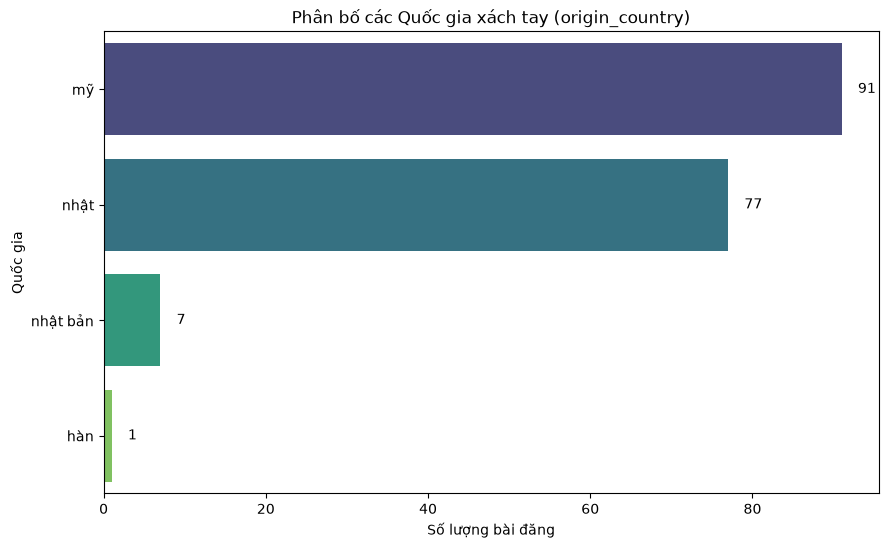

In [99]:
plt.figure(figsize=(10, 6))
country_counts = df['origin_country'].dropna().value_counts()
sns.barplot(x=country_counts.values, y=country_counts.index, palette='viridis')
plt.title('Phân bố các Quốc gia xách tay (origin_country)')
plt.xlabel('Số lượng bài đăng')
plt.ylabel('Quốc gia')

for i, v in enumerate(country_counts.values):
    plt.text(v + 2, i, str(v), color='black', va='center')
    
plt.show()

In [100]:
null_origin_country = df['origin_country'].isnull().sum()
print(f"Số bài đăng khuyết thông tin quốc gia xuất xứ: {null_origin_country}, chiếm {(null_origin_country / df.shape[0])*100:.2f} tổng số bài đăng")

Số bài đăng khuyết thông tin quốc gia xuất xứ: 3522, chiếm 95.24 tổng số bài đăng


## Warranty (Bảo hành)

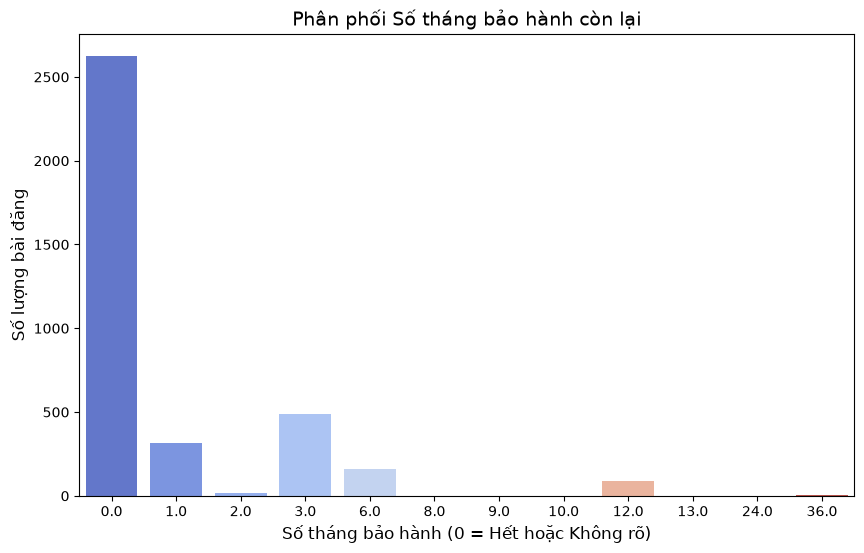

In [101]:
plt.figure(figsize=(10, 6))
df['warranty_months_eda'] = df['warranty_months'].fillna(0)
months_counts = df['warranty_months_eda'].value_counts().sort_index()
sns.barplot(x=months_counts.index, y=months_counts.values, palette='coolwarm')
plt.title('Phân phối Số tháng bảo hành còn lại', fontsize=14)
plt.xlabel('Số tháng bảo hành (0 = Hết hoặc Không rõ)', fontsize=12)
plt.ylabel('Số lượng bài đăng', fontsize=12)
plt.show()

In [102]:
has_warranty = (df['warranty_months_eda'] > 0).sum()
print(f"Tỷ lệ máy CÓ bảo hành: {has_warranty / len(df) * 100:.1f}%")

Tỷ lệ máy CÓ bảo hành: 29.0%


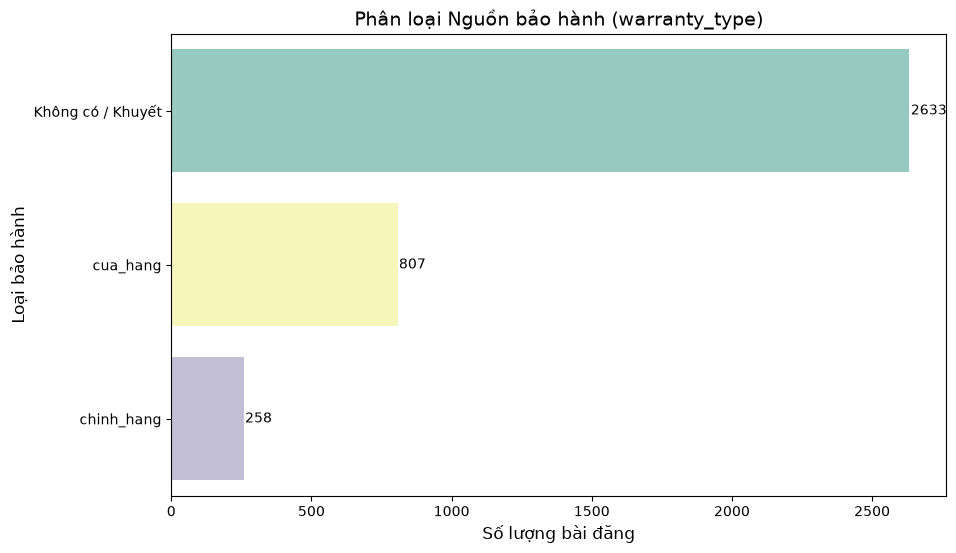

In [104]:
plt.figure(figsize=(10, 6))
type_counts = df['warranty_type'].fillna('Không có / Khuyết').value_counts()
sns.barplot(x=type_counts.values, y=type_counts.index, palette='Set3')
plt.title('Phân loại Nguồn bảo hành (warranty_type)', fontsize=14)
plt.xlabel('Số lượng bài đăng', fontsize=12)
plt.ylabel('Loại bảo hành', fontsize=12)

for i, v in enumerate(type_counts.values):
    plt.text(v + 5, i, str(v), color='black', va='center')
    
plt.show()

In [105]:
anomalies = df[(df['warranty_months_eda'] > 0) & (df['warranty_type'].isna())]
print(f"Số ca mâu thuẫn (Có tháng nhưng không rõ loại bảo hành): {len(anomalies)}")

Số ca mâu thuẫn (Có tháng nhưng không rõ loại bảo hành): 527


## Year Production

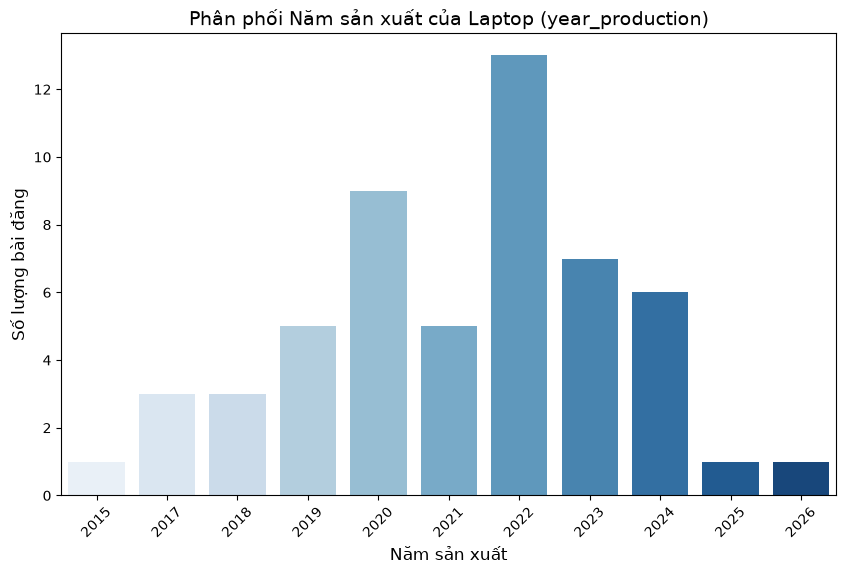

In [106]:
plt.figure(figsize=(10, 6))
valid_prod_years = df['year_production'].dropna().astype(int)
prod_counts = valid_prod_years.value_counts().sort_index()
sns.barplot(x=prod_counts.index, y=prod_counts.values, palette='Blues')
plt.title('Phân phối Năm sản xuất của Laptop (year_production)', fontsize=14)
plt.xlabel('Năm sản xuất', fontsize=12)
plt.ylabel('Số lượng bài đăng', fontsize=12)
plt.xticks(rotation=45)
plt.show()

In [107]:
outliers = valid_prod_years[(valid_prod_years < 2012) | (valid_prod_years > 2026)]
print(f"Phát hiện {len(outliers)} bài đăng có năm sản xuất vô lý hoặc quá cũ:")
print(outliers.unique())

Phát hiện 0 bài đăng có năm sản xuất vô lý hoặc quá cũ:
[]


## Year Purchase

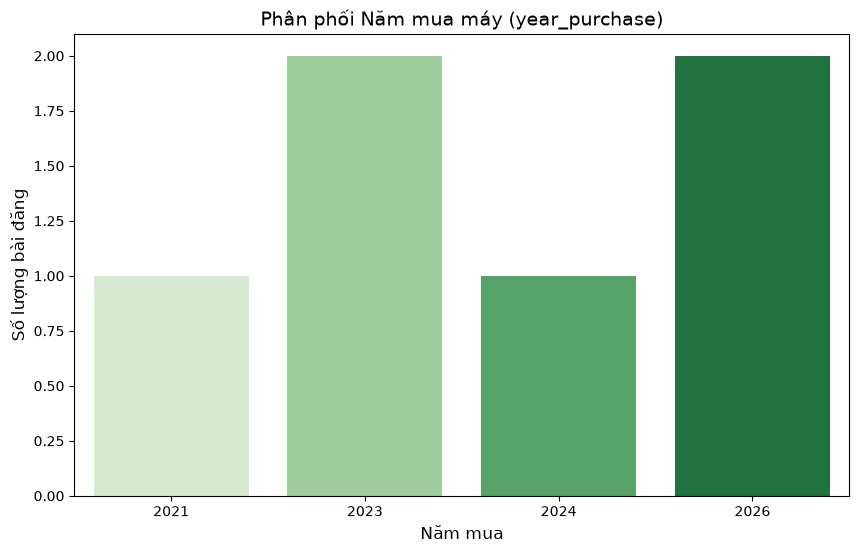

In [108]:
plt.figure(figsize=(10, 6))
valid_purch_years = df['year_purchase'].dropna().astype(int)
purch_counts = valid_purch_years.value_counts().sort_index()
sns.barplot(x=purch_counts.index, y=purch_counts.values, palette='Greens')
plt.title('Phân phối Năm mua máy (year_purchase)', fontsize=14)
plt.xlabel('Năm mua', fontsize=12)
plt.ylabel('Số lượng bài đăng', fontsize=12)
plt.show()

In [109]:
missing_purch = df['year_purchase'].isna().sum()
print(f"Số lượng bài đăng không ghi năm mua: {missing_purch} ({missing_purch/len(df)*100:.2f}%)")

Số lượng bài đăng không ghi năm mua: 3692 (99.84%)


## Bundles

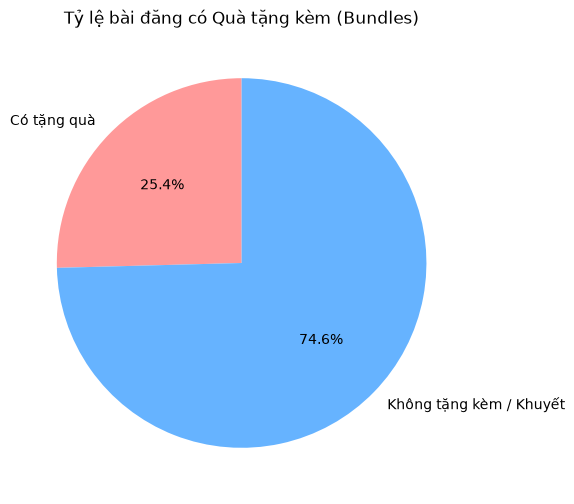

In [110]:
plt.figure(figsize=(6, 6))
has_bundle = df['bundles'].notna().sum()
no_bundle = df['bundles'].isna().sum()
plt.pie([has_bundle, no_bundle], labels=['Có tặng quà', 'Không tặng kèm / Khuyết'], autopct='%1.1f%%', colors=['#ff9999','#66b3ff'], startangle=90)
plt.title('Tỷ lệ bài đăng có Quà tặng kèm (Bundles)')
plt.show()

In [111]:
valid_bundles = df['bundles'].dropna().astype(str).str.lower()
split_bundles = valid_bundles.str.split(r'\s*,\s*|\s*\+\s*')
individual_items = split_bundles.explode().str.strip()
individual_items = individual_items[individual_items != '']
top_bundles = individual_items.value_counts().head(15)
print("Top 15 quà tặng kèm phổ biến nhất:")
print(top_bundles)

Top 15 quà tặng kèm phổ biến nhất:
bundles
túi chống sốc                                                                                                                                                                                                                                                                                                                                        108
chuột không dây                                                                                                                                                                                                                                                                                                                                       90
chuột                                                                                                                                                                                                                                                                      

---
# BIVARIATE & MULTIVARIATE ANALYSIS
---

## Giá theo Thương hiệu & Phân khúc (Brand & Production Line)

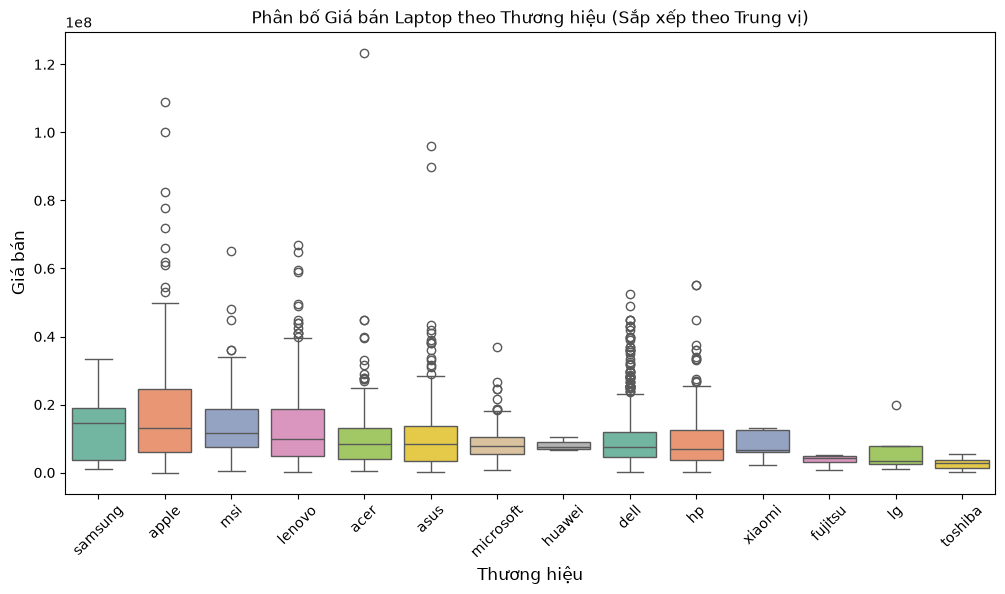

In [112]:
order = df.groupby("brand_name")["target_price"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(x='brand_name', y='target_price', data=df, order=order, palette='Set2')
plt.title("Phân bố Giá bán Laptop theo Thương hiệu (Sắp xếp theo Trung vị)")
plt.xlabel("Thương hiệu", fontsize=12)
plt.ylabel("Giá bán", fontsize=12)
plt.xticks(rotation=45)
plt.show()

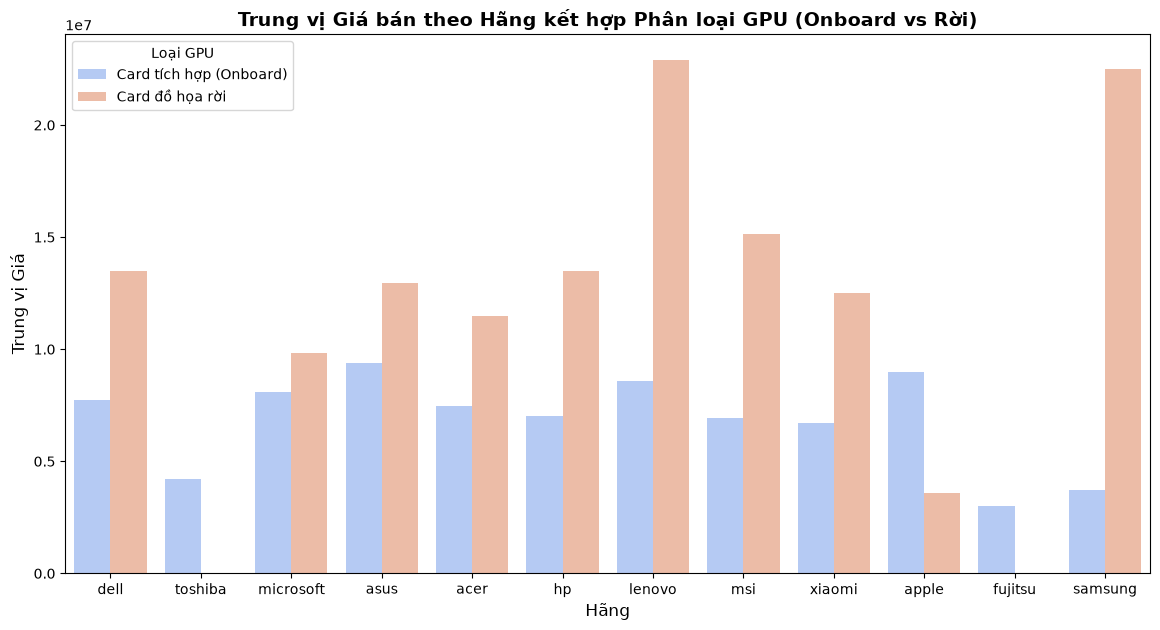

In [113]:
plt.figure(figsize=(14, 7))
sns.barplot(x='brand_name', y='target_price', hue='gpu_type', data=df[df['gpu_type'].notna()], estimator=np.median, ci=None, palette='coolwarm')
plt.title("Trung vị Giá bán theo Hãng kết hợp Phân loại GPU (Onboard vs Rời)", fontsize=14, fontweight='bold')
plt.xlabel("Hãng", fontsize=12)
plt.ylabel("Trung vị Giá", fontsize=12)
plt.legend(title="Loại GPU", labels=["Card tích hợp (Onboard)", "Card đồ họa rời"])
plt.show()

## Tác động của cấu hình máy lên giá (Hardware Configuration Impact)

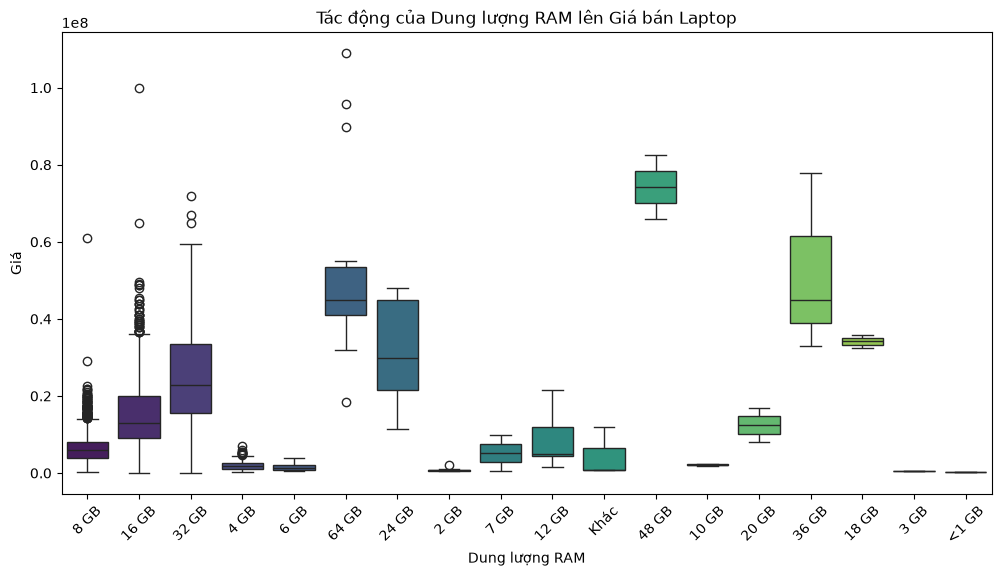

In [114]:
plt.figure(figsize=(12, 6))
valid_ram = df.dropna(subset=['raw_ram', 'target_price']).copy()
sns.boxplot(x='raw_ram', y='target_price', data=valid_ram, palette='viridis')
plt.title("Tác động của Dung lượng RAM lên Giá bán Laptop")
plt.xticks(rotation=45)
plt.xlabel("Dung lượng RAM")
plt.ylabel("Giá")
plt.show()

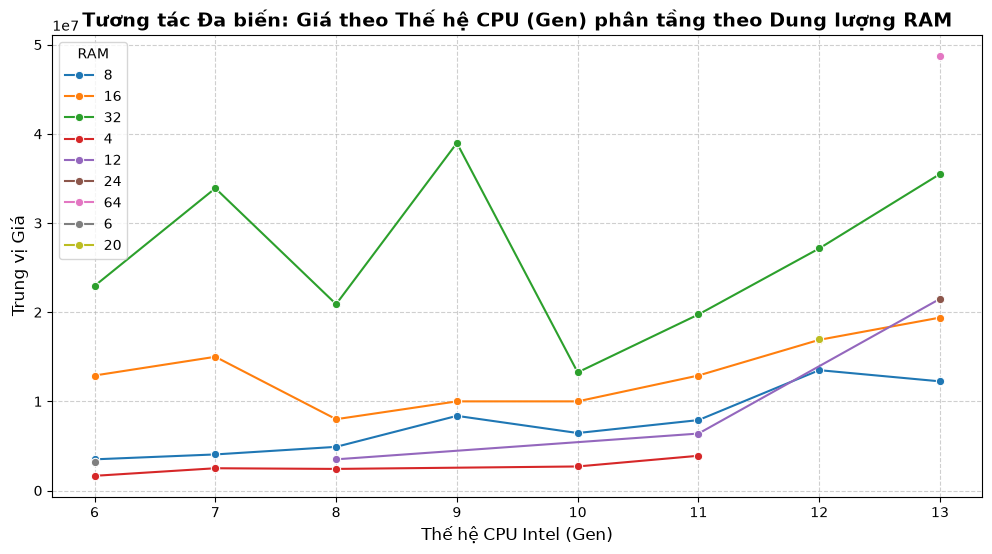

In [115]:
df_gen = df.copy()
df_gen['cpu_gen'] = pd.to_numeric(df_gen['cpu_gen'], errors='coerce')
df_gen['raw_ram'] = pd.to_numeric(
    df_gen['raw_ram'].astype('string').str.extract(r'(\d+(?:\.\d+)?)', expand=False),
    errors='coerce'
)

df_gen = df_gen.loc[
    df_gen['cpu_gen'].between(6, 13)
    & df_gen['raw_ram'].notna()
    & df_gen['target_price'].notna()
].copy()
df_gen['raw_ram'] = df_gen['raw_ram'].astype(int).astype(str)

plt.figure(figsize=(12, 6))
sns.lineplot(x='cpu_gen', y='target_price', hue='raw_ram', data=df_gen, marker='o', palette='tab10', estimator=np.median, ci=None)
plt.title("Tương tác Đa biến: Giá theo Thế hệ CPU (Gen) phân tầng theo Dung lượng RAM", fontsize=14, fontweight='bold')
plt.xlabel("Thế hệ CPU Intel (Gen)", fontsize=12)
plt.ylabel("Trung vị Giá", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title="RAM")
plt.show()

## Tác động của Độ mới & Bảo hành lên Giá (Condition & Warranty)

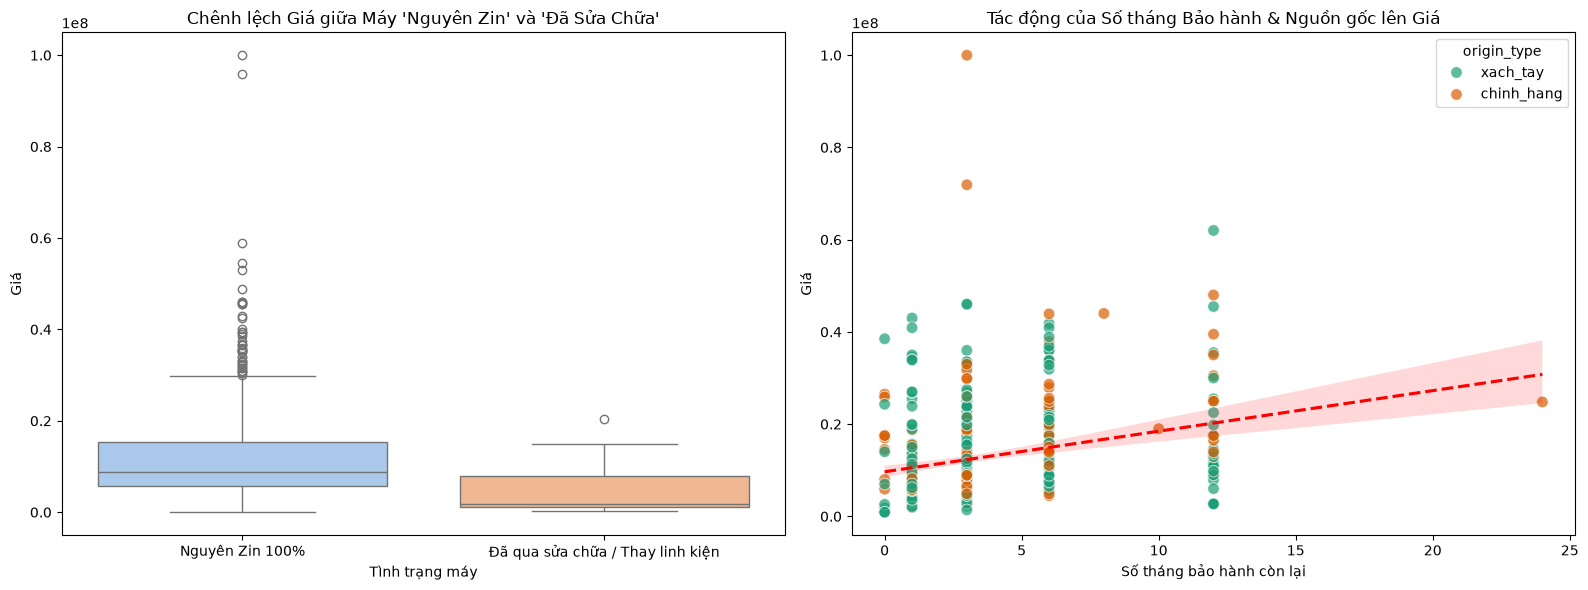

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

repair_order = ['original', 'repaired']
sns.boxplot(ax=axes[0], x='repair_status', y='target_price', data=df[df['repair_status'].isin(repair_order)], palette='pastel')
axes[0].set_title("Chênh lệch Giá giữa Máy 'Nguyên Zin' và 'Đã Sửa Chữa'")
axes[0].set_xlabel("Tình trạng máy")
axes[0].set_ylabel("Giá")
axes[0].set_xticklabels(["Nguyên Zin 100%", "Đã qua sửa chữa / Thay linh kiện"])

# 3.2 Multivariate: Thời hạn bảo hành kết hợp Nguồn gốc (Chính hãng vs Xách tay)
valid_origin = df.loc[
    df['origin_type'].notna()
    & df['warranty_months'].between(0, 24)
    & df['target_price'].notna()
].copy()

sns.scatterplot(
    ax=axes[1], x='warranty_months', y='target_price', hue='origin_type',
    data=valid_origin, alpha=0.7, s=70, palette='Dark2'
)
sns.regplot(
    ax=axes[1], x='warranty_months', y='target_price', 
    data=valid_origin, scatter=False, color='red', line_kws={'linestyle': '--'}
)
axes[1].set_title("Tác động của Số tháng Bảo hành & Nguồn gốc lên Giá")
axes[1].set_xlabel("Số tháng bảo hành còn lại")
axes[1].set_ylabel("Giá")

plt.tight_layout()
plt.show()

## Tương quan (Correlation)

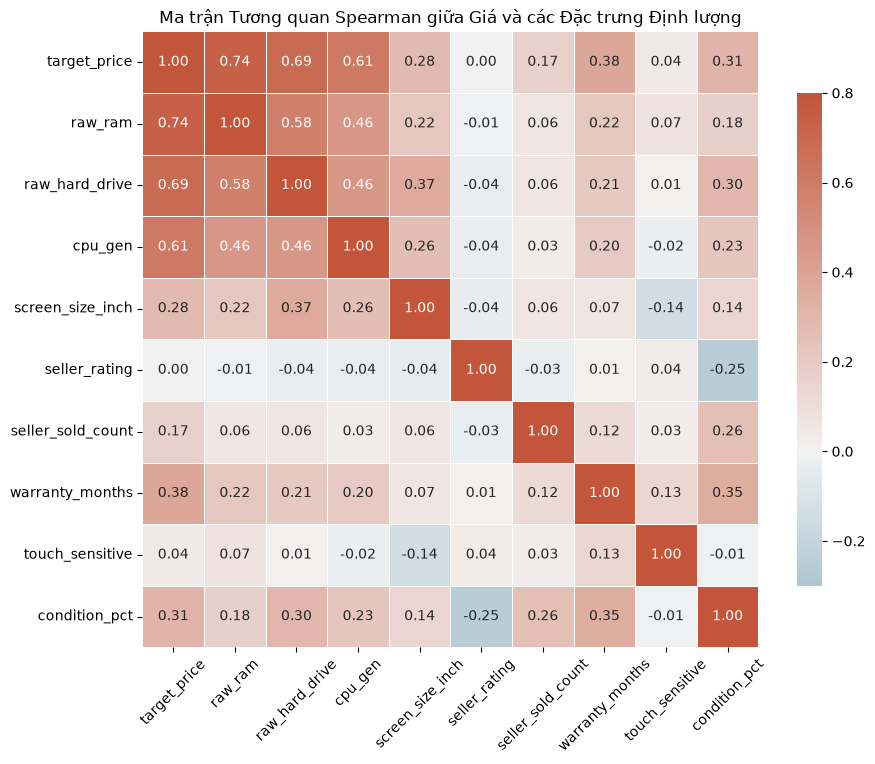

In [117]:
numeric_cols = [
    'target_price', 'raw_ram', 'raw_hard_drive', 'cpu_gen', 
    'screen_size_inch', 'seller_rating', 'seller_sold_count', 
    'warranty_months', 'touch_sensitive', 'condition_pct'
]
corr_data = df[numeric_cols].copy()

# Extract numeric capacities from values such as "8 GB" and "256 GB".
corr_data['raw_ram'] = pd.to_numeric(corr_data['raw_ram'].astype('string').str.extract(r'(\d+(?:\.\d+)?)', expand=False), errors='coerce')

# Convert storage capacities to GB; unparseable values become NaN.
storage = df['raw_hard_drive'].astype('string')
corr_data['raw_hard_drive'] = pd.to_numeric(storage.str.extract(r'(\d+(?:\.\d+)?)', expand=False), errors='coerce')
corr_data.loc[storage.str.contains(r'\bTB\b', case=False, na=False),'raw_hard_drive'] *= 1024

# Ensure every correlation input is numeric.
for col in numeric_cols:
    corr_data[col] = pd.to_numeric(corr_data[col], errors='coerce')

corr_spearman = corr_data.corr(method='spearman')

plt.figure(figsize=(10, 8))
#mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

cmap = sns.diverging_palette(230, 20, as_cmap=True)
sns.heatmap(corr_spearman, cmap=cmap, vmin=-0.3, vmax=0.8, center=0, square=True, linewidths=.5, cbar_kws={"shrink": .8}, annot=True, fmt=".2f")
plt.title("Ma trận Tương quan Spearman giữa Giá và các Đặc trưng Định lượng")
plt.xticks(rotation=45)
plt.show()

In [118]:
price_corr = corr_spearman['target_price'].drop('target_price').sort_values(ascending=False)
print("=== HỆ SỐ TƯƠNG QUAN VỚI GIÁ BÁN (TARGET_PRICE) ===")
print(price_corr.round(3))

=== HỆ SỐ TƯƠNG QUAN VỚI GIÁ BÁN (TARGET_PRICE) ===
raw_ram              0.739
raw_hard_drive       0.687
cpu_gen              0.612
warranty_months      0.382
condition_pct        0.311
screen_size_inch     0.283
seller_sold_count    0.166
touch_sensitive      0.043
seller_rating        0.002
Name: target_price, dtype: float64
